### **ABT de Métricas de Engajamento — Objeto Aluno**

Este notebook consolida 8 métricas de engajamento de alunos pagantes na plataforma, ou seja, matriculados não só no curso 96 -Comece por Aqui (que é gratuito), calculadas individualmente e unidas em uma ABT (Analytical Base Table) final, com granularidade por aluno. A sequência de cálculo e apresentação na ABT dessas métricas está abaixo (o número se refere a ordem na planilha ABT Métricas):

**Pilar 0 - Tempo de Relacionamento: Há quanto tempo ele é aluno da plataforma?** Traz a data de cadastro do aluno na plataforma (não é a data de matrícula atual) e há quantos dias ele é aluno, contados até a data_fim.

a) Métrica 12 - Data de Cadastro e Tempo como Aluno (em dias)

**Pilar 1 - Presença/Aproveitamento: Ele está ativo agora, e aproveita a plataforma quando acessa?** Mostra o estado presente: quanto ele usa a plataforma, há quanto tempo, com que regularidade, e se, quando acessa, assiste aulas ou apenas clica.

b) Métrica 05 - Número de Acessos (dias diferentes) por período e Taxa de Aproveitamento dos Acessos

c) Métrica 01 - Recência

d) Métrica 02 - Frequência Média na Plataforma

**Pilar 2 - Efetividade: O acesso, quando acontece, gera avanço real?** Separa "estar na plataforma" de "estar avançando/aprendendo".

e) Métrica 08 - Progresso e Velocidade do Progresso

f) Métrica 11 - Cursos Concluídos e Cursos em Andamento

e, futuramente, Nota Média/Taxa de Entrega

**Pilar 3 - Tendência da Evolução: A evolução dos acessos e do consumo de conteúdo está subindo, descendo, estável ou oscilando?** Mostra se o padrão de acesso e de consumo está em alta, queda, estabilidade ou oscilação, e o quanto essa tendência é confiável.

g) Métrica 06 - Histórico de Número de Acessos (Nota 1 e 2)

h) Métrica 09 - Evolução Mensal (Nota 2 e 3)


_(Nota 1)_ Uso do slope em substituição ao gráfico: a proposta original pedia um gráfico para analisar visualmente a tendência do número de acessos. Porém, para a inclusão da métrica na ABT, é necessário um valor numérico por aluno, e o slope (coeficiente angular) foi escolhido por sintetizar a tendência de engajamento, representando o comportamento da variação dos acessos no período analisado. Complementarmente, este notebook gera um gráfico de linha para os três alunos informados na célula de parametrização.

_(Nota 2)_ Uso do R²: ao analisar o slope, percebemos que somente ele por si só, embora mostre a direção da tendência, não gerava um número confiável, que poderia ser apenas reflexo de oscilação nos dados. O R² (coeficiente de determinação) então vem para complementar ao slope, medindo o quanto os acessos realmente seguem a reta de tendência calculada, ou seja, a dispersão dos pontos em torno dela.

_(Nota 3)_ Uso do slope de taxa: a proposta original pedia uma análise do comportamento mês a mês do número de acessos/tempo de aula assistida. Porém, para a inclusão da métrica na ABT, é necessário um valor numérico por aluno, e novamente o slope (coeficiente angular) foi escolhido, porém como taxa calculada considerando o número de dias da base dentro do mês correspondente, para não comparar meses parciais com meses completos. Complementarmente, este notebook gera um gráfico de linha para os três alunos informados na célula de parametrização.

_Resultados possíveis para slopes_
Positivo: demonstra tendência de aumento nos acessos.
Negativo: demonstra tendência de queda nos acessos.
Próximo de zero: sem tendência definida, pode significar estabilidade ou oscilação de forma que altos e baixos se compensem.

_Resultados possíveis para R2_
0 a 1: quanto mais próximo de 1, mais confiável é a tendência demonstrada pelo valor do slope. 

Limitação conhecida do slope: por ser uma tendência linear sobre todo o período, o slope pode não capturar reversões recentes de comportamento — por exemplo, um aluno com forte crescimento inicial seguido de queda nos últimos meses pode apresentar slope geral positivo, mesmo estando em processo de desengajamento no momento mais recente. Uma alternativa possível seria comparar o slope entre subperíodos (ex: primeira metade vs. segunda metade dos meses, ou slope ponderado dando mais peso aos meses recentes), capturando aceleração ou desaceleração da tendência. Optou-se por manter o cálculo atual (slope simples), dado que a ABT reúne outras métricas (como Recência) que ajudam a mitigar essa limitação isoladamente.


**Preparação das bases — correções, exclusões, validações, dados insuficientes e parametrização**

Antes das métricas, esta seção prepara as bases que serão usadas em todo o notebook e mostra o resultado de algumas validações necessárias para explicar considerações antes do cálculo de algumas métricas:

- **Carregamento, Correção de fuso horário e Exclusão de alunos não pagantes / cadastro teste - base alunos_geral - LISTA ALUNOS PAGANTES:** `cadastro` vem em UTC nos arquivos originais. Convertida para `TIMESTAMP_NTZ` para preservar o valor exato, sem conversão automática para o fuso local. Exclusão de alunos matriculados apenas no curso 96 (gratuito) e o cadastro teste 466, gerando a base `alunos_geral_filtrado`, usada em todas as métricas.
- **Carregamento, Correção de fuso horário, Exclusão de alunos não pagantes/cadastro teste e Exclusão de Matrículas que não sejam as ativas - base progresso_total:** `ultima_visualizacao` vem em UTC nos arquivos originais. Convertida para `TIMESTAMP_NTZ` para preservar o valor exato, sem conversão automática para o fuso local. Alunos matriculados apenas no curso 96 (gratuito) e o cadastro teste 466 são removidos, gerando a base `progresso_total_filtrado`, usada em todas as métricas.
- **Carregamento e Correção de fuso horário - base usuarios_geral:** `data_cadastro` vem em UTC (formato Zulu) nos arquivos originais. Convertida para `TIMESTAMP_NTZ` para preservar o valor exato, sem conversão automática para o fuso local. A base tem uma linha por aluno e não possui valores nulos ou NA nessa coluna, e é usada na métrica de Data de Cadastro e Tempo como Aluno.
- **Carregamento - asn_aulas_duracao:** para extração de dados sobre a duração das aulas.

- **NULL:** resposta para métricas onde não há registros suficientes para seu cálculo.

- **Validações 1 a 9:** estão no notebook **Proj EAD - Dicionário de Dados**. Resumo do que cada uma verifica e conclui:
  - **Validação 1 - Alunos não pagantes:** lista os alunos excluídos de `alunos_geral_filtrado` (matriculados somente no curso 96 e o cadastro teste 466). Resultado: 11 alunos excluídos (o 466 e 10 alunos só do curso 96).
  - **Validação 2 - Pagantes sem registro de acesso:** lista os alunos matriculados em cursos pagos que não têm nenhuma linha em `progresso_total`. Resultado: 6 alunos (207, 784, 1078, 1218, 1223 e 1227), que ficam com Número de Acessos igual a zero e as demais métricas de acesso NULL.
  - **Validação 3 - Alunos com pelo menos 2 datas de acesso:** conta as datas distintas de `ultima_visualizacao` e `data_conclusao` por aluno. Resultado: 51 alunos com 2 ou mais datas e 11 com menos de 2, que ficam NULL nas métricas que dependem de histórico (Frequência, Histórico de Acessos).
  - **Validação 4 - Linhas com `data_conclusao` nula:** lista as linhas de `progresso_total_filtrado` (sem os cursos 94, 29, 62 e 80) com `data_conclusao` nula, mostrando a porcentagem assistida da aula. Resultado: 15 linhas de 12 alunos, sendo 8 com porcentagem igual ou superior a 5% (todas na aula 4036 do curso 20), e que seriam perdidas na métrica 09 por falta de `data_conclusao`, considerando que o percentual_minimo_assistido usado foi de 5%.
  - **Validação 5 - Coerência entre `ultima_visualizacao` e `data_conclusao`:** compara, por aluno, a data máxima de `ultima_visualizacao` com a de `data_conclusao`. Resultado: nenhuma inconsistência (0 alunos), então `ultima_visualizacao` reflete o último acesso.
  - **Validação 6 - Cursos descontinuados:** lista os cursos de `alunos_geral` sem nenhuma aula em `asn_aulas_duracao`. Resultado: cursos 29, 62 e 80, excluídos das métricas 08, 09 e 11 (junto com o 94, somente agenda).
  - **Validação 7 - Aulas sem duração cadastrada:** lista os pares curso/aula de `progresso_total_filtrado` ausentes em `asn_aulas_duracao`, com o número de alunos e o tempo total assistido. Resultado: 6 aulas (cursos 29, 39 e 72), com no máximo 3 alunos cada e tempo total de 0 a 4min06s. Para a base atual o impacto nas métricas 05, 08, 09 e 11 é pequeno. Indica que é necessária verificação a cada mudança/atualização das bases, para avaliar o impacto de aulas e cursos descontinuados x performance do aluno.
  - **Validação 8 - Aulas por faixa de duração:** classifica as 749 aulas de `asn_aulas_duracao` em 6 faixas e conta os cursos de cada uma. Resultado: faixa 1 (menor que 10 minutos) 84 aulas em 15 cursos, faixa 2 (de 10 a 30 minutos) 200 aulas em 15 cursos, faixa 3 (de 30 minutos a 1 hora) 112 aulas em 12 cursos, faixa 4 (de 1 a 2 horas) 58 aulas em 15 cursos, faixa 5 (de 2 a 3 horas e 30 minutos) 289 aulas em 35 cursos, e faixa 6 (mais de 3 horas e 30 minutos) 6 aulas em 3 cursos.
  - **Validação 9 - Cursos por faixa de carga horária:** soma a duração de todas as aulas de cada curso e classifica os 47 cursos em 7 faixas. Resultado: faixa 1 (menos de 3 horas) 7 cursos, faixa 2 (de 3 a 5 horas) 4 cursos, faixa 3 (de 5 a 10 horas) 11 cursos, faixa 4 (de 10 a 25 horas) 15 cursos, faixa 5 (de 25 a 50 horas) 4 cursos, faixa 6 (de 50 a 100 horas) 4 cursos, e faixa 7 (100 horas ou mais) 2 cursos.

- **Parametrização manual:** `data_inicio`, `data_fim`, `tamanho_periodo` e `percentual_minimo_assistido`, mais os alunos de exemplo (`aluno_1/2/3` para os gráficos comparativos de linha e `aluno_4/5` para os gráficos individuais), são definidos como widgets, permitindo reaplicar este notebook em outros períodos/bases sem alterar a lógica e gerar os gráficos de linha para outros alunos.

In [0]:
%sql

/* CARREGAMENTO, CORREÇÃO DE FUSO HORÁRIO E EXCLUSÃO DE ALUNOS NÃO PAGANTES E CADASTRO TESTE - BASE alunos_geral - LISTA ALUNOS PAGANTES

Objetivo: Organização da estrutura dentro do Databricks. Para esse notebook, foi criado via catalog um novo catálogo para concentrar
as informações do projeto, com nome de "proj_ead". Dentro de "proj_ead" foi criado o schema "bases", para o Volume "bases", para upload das bases 
em .csv. Dentro de proj_ead através do código abaixo é criado o schema tabelas_metricas_aluno para armazenagem de todas as tabelas criadas 
por esse código*/

CREATE SCHEMA IF NOT EXISTS proj_ead.tabelas_metricas_aluno;

/* Objetivo: 1. Carregar alunos_geral. 2. Corrigir fuso na coluna cadastro. 3. Gerar tabela alunos_geral_filtrado, excluindo quem só está
matriculado no curso 96 (gratuito, não pagante) e o aluno 466 (cadastro de teste, não é aluno real).*/


CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.alunos_geral AS
SELECT
    * EXCEPT (cadastro),
    CAST(cadastro AS TIMESTAMP_NTZ) AS cadastro
FROM read_files('/Volumes/proj_ead/bases/bases/alunos_geral.csv', format => 'csv', header => true);

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado AS
WITH cursos_distintos AS (
    SELECT aluno_id, COUNT(DISTINCT curso_id) AS qtd_cursos_distintos
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral
    GROUP BY aluno_id
),
somente_curso_96 AS (
    SELECT c.aluno_id
    FROM cursos_distintos c
    JOIN proj_ead.tabelas_metricas_aluno.alunos_geral a ON c.aluno_id = a.aluno_id
    WHERE c.qtd_cursos_distintos = 1 AND a.curso_id = 96
    GROUP BY c.aluno_id
)
SELECT DISTINCT aluno_id
FROM proj_ead.tabelas_metricas_aluno.alunos_geral
WHERE aluno_id NOT IN (SELECT aluno_id FROM somente_curso_96)
  AND aluno_id != 466;

SELECT * FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado ORDER BY aluno_id LIMIT 10;

aluno_id
207
428
769
784
882
1033
1078
1079
1080
1083


In [0]:
%sql

/* CARREGAMENTO, CORREÇÃO DE FUSO HORÁRIO, EXCLUSÃO DE ALUNOS NÃO PAGANTES/CADASTRO TESTE E MATRÍCULAS INATIVAS - BASE progresso_total
Objetivo: 1. Carregar progresso_total. 2. Corrigir fuso na coluna ultima_visualizacao. 3. Gerar tabela progresso_total_filtrado,
excluindo não pagantes e o aluno 466 (via alunos_geral_filtrado), e mantendo apenas linhas onde a matrícula do aluno naquele curso 
específico está com status 'Matrícula ativa' (JOIN por aluno_id + curso_id com alunos_geral). Isso evita contar acessos de matrículas 
inativas em qualquer métrica calculada a partir desta tabela. */


CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.progresso_total AS
SELECT
    * EXCEPT (ultima_visualizacao),
    CAST(ultima_visualizacao AS TIMESTAMP_NTZ) AS ultima_visualizacao
FROM read_files('/Volumes/proj_ead/bases/bases/progresso_total.csv', format => 'csv', header => true);

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.progresso_total_filtrado AS
SELECT p.*
FROM proj_ead.tabelas_metricas_aluno.progresso_total p
JOIN proj_ead.tabelas_metricas_aluno.alunos_geral a ON p.aluno_id = a.aluno_id AND p.curso_id = a.curso_id
WHERE p.aluno_id IN (SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado)
  AND a.status = 'Matrícula ativa';

SELECT * FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado LIMIT 10;

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,tempo_aula,data_conclusao,aula_concluido,_rescued_data,ultima_visualizacao
217,20,IDA,217,1118,O que é probabilidade?,1215,00:20:41,2026-01-09T19:41:10Z,1,null,2026-01-09T19:57:25.000
217,20,IDA,217,1118,O que é probabilidade?,1201,00:29:14,2025-12-09T18:13:35Z,1,null,2025-12-28T21:03:50.000
217,20,IDA,217,1118,O que é probabilidade?,1195,00:16:53,2025-12-21T01:58:57Z,1,null,2026-01-14T11:04:14.000
217,20,IDA,217,1118,O que é probabilidade?,1224,00:16:39,2026-01-06T19:22:41Z,1,null,2026-01-11T16:15:57.000
217,20,IDA,217,1118,O que é probabilidade?,1213,00:14:48,2026-01-06T11:36:58Z,1,null,2026-01-07T08:46:31.000
217,20,IDA,217,1118,O que é probabilidade?,1090,00:16:01,2025-11-24T14:55:22Z,1,null,2025-11-24T15:10:35.000
217,20,IDA,217,1118,O que é probabilidade?,1080,00:15:35,2025-11-23T23:22:10Z,1,null,2025-11-23T23:35:51.000
217,20,IDA,217,1119,Distribuição Estatística,1215,00:43:40,2026-01-09T20:15:01Z,1,null,2026-01-09T20:38:15.000
217,20,IDA,217,1119,Distribuição Estatística,1201,01:54:06,2025-12-09T18:31:37Z,1,null,2025-12-28T21:50:19.000
217,20,IDA,217,1119,Distribuição Estatística,1195,00:44:57,2026-01-11T13:13:50Z,1,null,2026-01-14T11:08:50.000


In [0]:
%sql

/* CARREGAMENTO E CORREÇÃO DE FUSO HORÁRIO - BASE usuarios_geral
Objetivo: 1. Carregar usuarios_geral (uma linha por aluno). 2. Corrigir fuso na coluna data_cadastro (formato Zulu), convertendo para TIMESTAMP_NTZ. Nota: a coluna não tem valores nulos ou NA. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.usuarios_geral AS
SELECT
    * EXCEPT (data_cadastro),
    CAST(data_cadastro AS TIMESTAMP_NTZ) AS data_cadastro
FROM read_files('/Volumes/proj_ead/bases/bases/usuarios_geral.csv', format => 'csv', header => true);

SELECT * FROM proj_ead.tabelas_metricas_aluno.usuarios_geral LIMIT 100;

aluno_id,ultimo_acesso,uf,tipo,status,username,_rescued_data,data_cadastro
1102,2026-01-18T17:44:57Z,NA,1,1,Aluno,null,2025-11-18T22:14:39.000
1196,2026-01-20T17:15:26Z,NA,1,1,Aluno,null,2025-11-28T10:09:14.000
1085,2026-01-23T14:21:54Z,NA,1,1,Aluno,null,2025-11-18T21:16:13.000
1200,2026-01-20T13:47:45Z,NA,1,1,Aluno,null,2025-11-28T14:01:21.000
1103,2026-01-21T20:51:52Z,NA,1,1,Aluno,null,2025-11-18T22:18:43.000
1088,2026-01-23T08:10:54Z,NA,1,1,Aluno,null,2025-11-18T21:29:47.000
1099,2026-01-23T08:59:55Z,NA,1,1,Aluno,null,2025-11-18T21:56:19.000
1087,2026-01-23T11:08:57Z,NA,1,1,Aluno,null,2025-11-18T21:29:29.000
1215,2026-01-23T13:20:33Z,NA,1,1,Aluno,null,2025-11-28T21:25:55.000
1201,2026-01-24T00:05:49Z,NA,1,1,Aluno,null,2025-11-28T14:06:58.000


In [0]:
%sql

/* CARREGAMENTO DA BASE asn_aulas_duracao:
Objetivo: 1. Carregar a base de duração das aulas, necessária em métricas que usam a contagem total de cursos e aulas, ou tempo de duração total das aulas.*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.asn_aulas_duracao AS
SELECT * 
FROM read_files('/Volumes/proj_ead/bases/bases/asn_aulas_duracao.csv',
    format => 'csv',
    header => true,
    quote => '"',
    escape => '"'
);
SELECT * FROM proj_ead.tabelas_metricas_aluno.asn_aulas_duracao LIMIT 10;

curso_id,curso,modulo_id,modulo,aula_id,aula,duracao_segundos,duracao_hhmmss,_rescued_data
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4675,Redes neurais: do perceptron às arquiteturas modernas,10461.0,02:54:21,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4676,"Redes neurais profundas: arquitetura, targets e aprendizado",10162.0,02:49:22,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4677,Redes neurais: aprendizado de parâmetros e backpropagation,9628.0,02:40:28,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4678,"Redes neurais: inicialização, escala e regularização",9436.0,02:37:16,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4679,Redes neurais convolucionais: aprendendo padrões em imagens,9893.0,02:44:53,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4680,"Arquiteturas clássicas de CNNs, detecção de objetos e transfer learning",10406.0,02:53:26,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4681,Redes neurais: segmentação semântica e reconhecimento facial,9749.0,02:42:29,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4682,Redes neurais para texto: embeddings e modelos sequenciais,10643.0,02:57:23,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4683,"Modelos sequenciais avançados: LSTM, GRU e Transformers",10452.0,02:54:12,null
39,Redes Neurais e Inteligência Artificial - Prof° Bruno Leme,697,Redes Neurais e Inteligência Artificial,4684,Transformers e modelos de linguagem: do BERT ao GPT,11362.0,03:09:22,null


In [0]:
# CÉLULA DE PARAMETRIZAÇÃO
# a. Parâmetros de inclusão manual - altere os valores nas caixas de widget no topo da tela para trocar: data inicial, data final, tamanho do período
# (em dias) para métrica 6, id dos alunos (aluno_1 a aluno_5) para construção dos gráficos de linha das métricas 6 e 9, percentual mínimo assistido 
# usado nas métricas 05, 09 e 11
# b. Para cada aluno, o início do cálculo é o maior valor entre data_inicio e sua data de matrícula (evitando prejudicar quem se matriculou depois 
# de data_inicio). 
# c. O número de períodos (para métrica 6) é contado a partir do início efetivo de cada aluno (o maior entre data_inicio e a data de matrícula) até 
# data_fim, para não prejudicar nessa base alunos matriculados em 28/11, criando um período inicial zerado artificial. 
# d. A escolha inicial do tamanho do período para essa amostra (de 18/11/2025 a 26/01/2026) considerou que a base de dados se refere a alunos 
# matriculados em 18/11 e 28/11, com 10 dias de diferença entre eles. 
# Nota: Minha sugestão para uma base maior é período de 7 dias ou múltiplos, pois acompanharia a influência da agenda do aluno, considerando seus 
# compromissos externos ao curso.
# e. aluno_1, aluno_2 e aluno_3 - Grupo de alunos selecionados para construção do gráfico de linha de histórico de número de acessos e evolução mensal.
# f. aluno_4 e aluno_5 - Alunos selecionados para construção do gráficos individuais de linha de histórico de número de acessos e evolução mensal.
# g. percentual_minimo_assistido: percentual mínimo em relação a duração da aula, assistido para considerá-la no cálculo, evitando cliques sem objetivo 
# de estudo (critério de Volume), para uso nas métricas 05, 09 e 11.

dbutils.widgets.text("data_inicio", "2025-11-18")
dbutils.widgets.text("data_fim", "2026-01-26")
dbutils.widgets.text("tamanho_periodo", "10")
dbutils.widgets.text("aluno_1", "1086")
dbutils.widgets.text("aluno_2", "1088")
dbutils.widgets.text("aluno_3", "1222")
dbutils.widgets.text("aluno_4", "1083")
dbutils.widgets.text("aluno_5", "1033")
dbutils.widgets.text("percentual_minimo_assistido", "0.05")

**_Métrica 12 - Data de Cadastro e Tempo como Aluno (em dias):_** Identificar a data em que o aluno se cadastrou na plataforma (não é a data de matrícula atual) e há quantos dias ele é aluno, contados da data de cadastro até a data de corte (para a base atual, 26/01/2026).

In [0]:
%sql

/* DATA DE CADASTRO E TEMPO DE CADASTRO DE CADA ALUNO PAGANTE
Objetivo: 1. Trazer a data de cadastro do aluno na plataforma (data_cadastro, apenas a data, sem horário), a partir de usuarios_geral. 2. Calcular o tempo de cadastro (dias_cadastro): dias decorridos entre data_cadastro e data_fim, sem +1 (cadastro e data_fim no mesmo dia resulta em 0).
Nota: aluno pagante sem registro em usuarios_geral tem as duas colunas NULL. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_cadastro AS
SELECT
    t.aluno_id,
    DATE(u.data_cadastro) AS data_cadastro,
    DATEDIFF(DATE(:data_fim), DATE(u.data_cadastro)) AS dias_cadastro
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN proj_ead.tabelas_metricas_aluno.usuarios_geral u ON t.aluno_id = u.aluno_id
ORDER BY t.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_cadastro LIMIT 70;

aluno_id,data_cadastro,dias_cadastro
207,2024-05-08,628
428,2024-09-05,508
769,2025-07-24,186
784,2025-08-04,175
882,2025-09-26,122
1033,2025-10-24,94
1078,2025-11-18,69
1079,2025-11-18,69
1080,2025-11-18,69
1083,2025-11-18,69


**_Métrica 05 - Número de acessos (dias diferentes) por período e Taxa de Aproveitamento dos Acessos:_** Identificar em quantos dias distintos o aluno acessou a plataforma dentro de um período definido, e a proporção desses dias em que ele assistiu de fato pelo menos uma aula (mínimo de 5% da duração), e não apenas clicou. O período começa no maior valor entre data_inicio e a matrícula do aluno e termina na data de corte (para a base atual, 26/01/2026). A taxa complementa o número de acessos ao mostrar, para cada aluno, se ao entrar ele estuda ou apenas clica, e vai de 0 a 1: perto de 0, poucos dias de acesso com aula de fato assistida; perto de 1, na maioria dos dias em que entra, tende a assistir e não só clicar.

In [0]:
%sql

/* NÚMERO DE DIAS DISTINTOS DE ACESSO E TAXA DE APROVEITAMENTO DOS ACESSOS DE CADA ALUNO PAGANTE
Objetivo: 1. Calcular o Número de Acessos (numero_acessos_dias_distintos): dias distintos (com ultima_visualizacao ou data_conclusao), entre data_inicio ou cadastro do aluno (o que for maior) e data_fim. 2. Calcular a Taxa de Aproveitamento dos Acessos (taxa_aproveit_acessos): mostra a proporção dos dias de acesso em que o aluno assistiu pelo menos uma aula (critério para aula assistida: percentual_minimo_assistido). Vai de 0 a 1: perto de 0, poucos dias de acesso com aula de fato assistida (predominam cliques); perto de 1, na maioria dos dias em que entra, tende a assistir e não só clicar.
Nota 1: aluno sem acesso tem Número de Acessos igual a zero (Validação 2) e Taxa NULL (denominador zero).
Nota 2: cada aula tem no máximo duas datas (ultima_visualizacao e data_conclusao): se iguais, conta uma vez; se diferentes, conta nos dois dias.*/


CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_acessos AS
WITH data_inicio_aluno AS (
    SELECT
        ag.aluno_id,
        GREATEST(DATE(:data_inicio), MAX(DATE(a.cadastro))) AS data_inicio_efetiva
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado ag
    JOIN proj_ead.tabelas_metricas_aluno.alunos_geral a ON ag.aluno_id = a.aluno_id
    GROUP BY ag.aluno_id
),
aulas AS (
    SELECT
        p.aluno_id,
        p.ultima_visualizacao,
        TRY_CAST(p.data_conclusao AS TIMESTAMP) AS data_conclusao_ts,
        CASE
            WHEN d.duracao_segundos IS NULL OR d.duracao_segundos = 0 THEN 0
            WHEN (TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 1) AS INTEGER) * 3600
                    + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 2) AS INTEGER) * 60
                    + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 3) AS INTEGER)) / d.duracao_segundos
                 >= CAST(:percentual_minimo_assistido AS DOUBLE) THEN 1
            ELSE 0
        END AS aula_assistida
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado p
    LEFT JOIN proj_ead.tabelas_metricas_aluno.asn_aulas_duracao d
        ON p.curso_id = d.curso_id AND p.aula_id = d.aula_id
),
datas_acesso AS (
    SELECT
        a.aluno_id,
        DATE(a.ultima_visualizacao) AS data_acesso,
        a.aula_assistida
    FROM aulas a
    JOIN data_inicio_aluno d ON a.aluno_id = d.aluno_id
    WHERE a.ultima_visualizacao IS NOT NULL
      AND DATE(a.ultima_visualizacao) BETWEEN d.data_inicio_efetiva AND :data_fim
    UNION ALL
    SELECT
        a.aluno_id,
        DATE(a.data_conclusao_ts) AS data_acesso,
        a.aula_assistida
    FROM aulas a
    JOIN data_inicio_aluno d ON a.aluno_id = d.aluno_id
    WHERE a.data_conclusao_ts IS NOT NULL
      AND DATE(a.data_conclusao_ts) BETWEEN d.data_inicio_efetiva AND :data_fim
),
dias_acesso AS (
    SELECT
        aluno_id,
        data_acesso,
        MAX(aula_assistida) AS dia_aproveitado
    FROM datas_acesso
    GROUP BY aluno_id, data_acesso
),
contagem AS (
    SELECT
        aluno_id,
        COUNT(*) AS numero_acessos_dias_distintos,
        SUM(dia_aproveitado) AS dias_aproveitados
    FROM dias_acesso
    GROUP BY aluno_id
)
SELECT
    t.aluno_id,
    COALESCE(c.numero_acessos_dias_distintos, 0) AS numero_acessos_dias_distintos,
    CASE
        WHEN COALESCE(c.numero_acessos_dias_distintos, 0) = 0 THEN NULL
        ELSE CAST(c.dias_aproveitados * 1.0 / c.numero_acessos_dias_distintos AS DECIMAL(18,6))
    END AS taxa_aproveit_acessos
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN contagem c ON t.aluno_id = c.aluno_id
ORDER BY t.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_acessos LIMIT 63;

aluno_id,numero_acessos_dias_distintos,taxa_aproveit_acessos
207,0,null
428,1,0.000000
769,21,0.857143
784,0,null
882,11,1.000000
1033,21,0.666667
1078,0,null
1079,14,1.000000
1080,24,0.958333
1083,6,0.000000


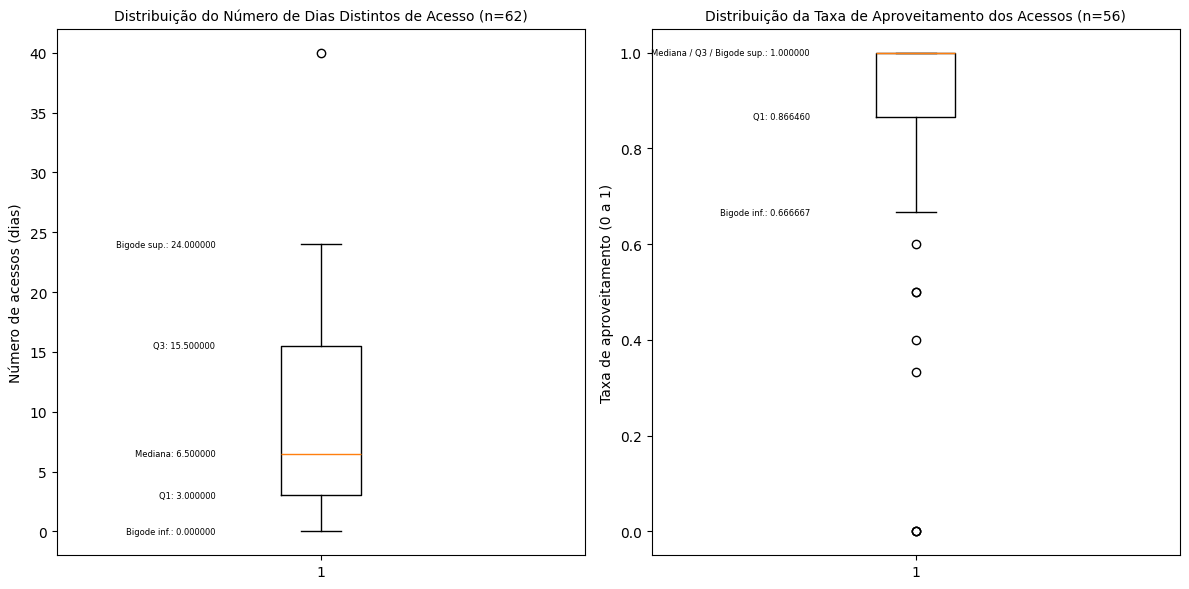

In [0]:
# Boxplot para análise da distribuição do Número de Dias Distintos de Acesso (62 alunos pagantes) e da Taxa de Aproveitamento dos Acessos (56 alunos pagantes com pelo menos um dia de acesso).

import matplotlib.pyplot as plt
import pandas as pd

df_acessos = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_acessos").toPandas()
df_acessos['numero_acessos_dias_distintos'] = pd.to_numeric(df_acessos['numero_acessos_dias_distintos'], errors='coerce')
df_acessos['taxa_aproveit_acessos'] = pd.to_numeric(df_acessos['taxa_aproveit_acessos'], errors='coerce')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, coluna, titulo, unidade in [
    (axes[0], 'numero_acessos_dias_distintos', 'Distribuição do Número de Dias Distintos de Acesso', 'Número de acessos (dias)'),
    (axes[1], 'taxa_aproveit_acessos', 'Distribuição da Taxa de Aproveitamento dos Acessos', 'Taxa de aproveitamento (0 a 1)')
]:
    dados_validos = df_acessos[coluna].dropna()
    bp = ax.boxplot(dados_validos, vert=True)
    ax.set_title(f'{titulo} (n={len(dados_validos)})', fontsize=10)
    ax.set_ylabel(unidade)
    mediana = bp['medians'][0].get_ydata()[0]
    q1 = bp['boxes'][0].get_ydata()[0]
    q3 = bp['boxes'][0].get_ydata()[2]
    bigode_inferior = bp['whiskers'][0].get_ydata()[1]
    bigode_superior = bp['whiskers'][1].get_ydata()[1]

    # Agrupa rótulos de valores iguais (ex.: Mediana = Q3 = Bigode sup.) em uma única linha
    rotulos = {}
    for valor, nome in [(mediana, 'Mediana'), (q1, 'Q1'), (q3, 'Q3'),
                        (bigode_inferior, 'Bigode inf.'), (bigode_superior, 'Bigode sup.')]:
        rotulos.setdefault(round(valor, 6), []).append(nome)

    # Afasta verticalmente rótulos muito próximos
    faixa = ax.get_ylim()[1] - ax.get_ylim()[0]
    passo = faixa * 0.04
    ultimo_y = None
    for valor in sorted(rotulos, reverse=True):
        y_texto = valor
        if ultimo_y is not None and ultimo_y - y_texto < passo:
            y_texto = ultimo_y - passo
        ultimo_y = y_texto
        ax.text(0.8, y_texto, f"{' / '.join(rotulos[valor])}: {valor:.6f}", va='center', ha='right', fontsize=6)
plt.tight_layout()
plt.show()

**Interpretação — Distribuição do Número de Dias Distintos de Acesso:** A maior parte dos alunos tem um volume de acesso baixo: metade da base, cerca de 31 alunos (50% de 62), acessou a plataforma em apenas 6,5 dias distintos ao longo de todo o período (mediana = 6,5), e aproximadamente 16 alunos (25%) acessaram em 3 dias ou menos (Q1 = 3). O grupo com engajamento razoável está entre a mediana e o Q3, cerca de 16 alunos (25%) que acessaram de 6,5 a 15,5 dias distintos, aproximando-se de um ritmo semanal de estudo. Já os alunos mais engajados estão no extremo superior: cerca de 15 alunos (25%) acessaram entre 15,5 e 24 dias distintos (Q3 até o bigode superior = 24), alguns chegando a acessar mais de duas vezes por semana, em média. Um aluno se destaca como outlier, com 40 dias distintos de acesso — um volume excepcional, bem acima do padrão da turma.


**Interpretação — Distribuição da Taxa de Aproveitamento dos Acessos:** A maior parte dos alunos aproveita bem os dias em que entra: pelo menos metade da base, cerca de 28 alunos (50% de 56), assistiu pelo menos uma aula em todos os dias de acesso (mediana = 1,0). Como a taxa não passa de 1, mediana, Q3 e bigode superior coincidem no teto da escala, e o Q1 = 0,87 indica que 75% dos alunos assistiram aula em pelo menos 87% dos dias de acesso. O bigode inferior chega a 0,67, ou seja, mesmo os alunos com menor aproveitamento dentro do padrão assistiram aula em pelo menos dois a cada três dias de acesso. Abaixo disso aparecem outliers, com taxas de aproximadamente 0,60, 0,50 (2 alunos), 0,40 e 0,33, além dos 3 alunos com taxa 0, que acessaram a plataforma sem assistir de fato nenhuma aula, apenas clicando.

**_Métrica 01 - Recência:_** Identificar há quanto tempo o aluno não entra na plataforma, ou seja, a diferença de dias entre o último acesso e a data de corte (data_fim).

In [0]:
%sql

/*RECÊNCIA (EM DIAS) DE CADA ALUNO PAGANTE 
Objetivo: 1. Calcular a métrica de Recência, considerando a data_fim como data de extração da base de dados. 2. Alunos pagantes sem nenhum registro em progresso_total_filtrado (nunca acessaram) recebem valor nulo, mantendo a coluna numérica. Nota: para alunos sem acesso a nenhuma aula, valor da métrica igual a NULL (Validação 2) */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_recencia AS
WITH recencia_calculada AS (
    SELECT
        aluno_id,
        MAX(ultima_visualizacao) AS ultima_visualizacao,
        CAST(DATEDIFF(TRY_CAST(:data_fim AS DATE), TRY_CAST(MAX(ultima_visualizacao) AS DATE)) AS DECIMAL(18,6)) AS recencia
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
    GROUP BY aluno_id
)
SELECT
    t.aluno_id,
    r.ultima_visualizacao,
    r.recencia AS recencia
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN recencia_calculada r ON t.aluno_id = r.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_recencia LIMIT 4000;

aluno_id,ultima_visualizacao,recencia
1090,2026-01-09T12:54:33.000,17.000000
1204,2025-12-05T09:33:54.000,52.000000
1207,2026-01-24T15:24:07.000,2.000000
1202,2026-01-15T22:01:00.000,11.000000
1205,2026-01-05T10:02:42.000,21.000000
1226,2026-01-10T19:49:04.000,16.000000
1232,2025-11-30T08:26:49.000,57.000000
1105,2025-11-24T14:01:32.000,63.000000
1227,null,null
1203,2026-01-12T12:01:56.000,14.000000


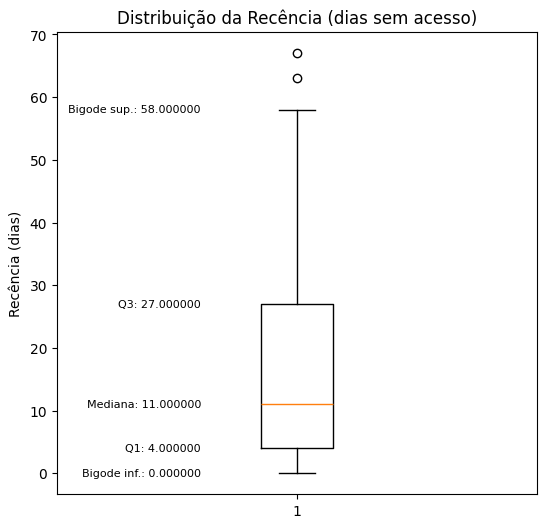

In [0]:
# Boxplot para análise da distribuição da métrica de Recência (dias sem acesso) para alunos pagantes com pelo menos um acesso a qualquer aula (56 alunos).

import matplotlib.pyplot as plt
import pandas as pd

df_recencia = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_recencia").toPandas()

df_recencia['recencia'] = pd.to_numeric(df_recencia['recencia'], errors='coerce')
dados_validos = df_recencia['recencia'].dropna()

fig, ax = plt.subplots(figsize=(8, 6))
plt.subplots_adjust(left=0.3)
bp = ax.boxplot(dados_validos, vert=True)
plt.title('Distribuição da Recência (dias sem acesso)')
plt.ylabel('Recência (dias)')
mediana = bp['medians'][0].get_ydata()[0]
q1 = bp['boxes'][0].get_ydata()[0]
q3 = bp['boxes'][0].get_ydata()[2]
bigode_inferior = bp['whiskers'][0].get_ydata()[1]
bigode_superior = bp['whiskers'][1].get_ydata()[1]
for valor, nome in [(mediana, 'Mediana'), (q1, 'Q1'), (q3, 'Q3'),
                     (bigode_inferior, 'Bigode inf.'), (bigode_superior, 'Bigode sup.')]:
    plt.text(0.8, valor, f'{nome}: {valor:.6f}', va='center', ha='right', fontsize=8)
plt.show()

**Interpretação — Distribuição da Recência:** Essa análise considera apenas os 56 alunos, os que têm pelo menos um acesso registrado. Entre esses, a maior parte está engajada a um nível aceitável: metade, cerca de 28 alunos (50% de 56), acessou a plataforma há no máximo 11 dias (mediana = 11), menos de duas semanas, e aproximadamente 14 alunos (25%) há no máximo 4 dias (Q1 = 4). O grupo de atenção começa a partir daí: cerca de 14 alunos (25%), entre a mediana (11) e o Q3 (27), já estão quase acima de duas semanas e até mais de três semanas sem acesso, faixa preocupante. Mas o risco de evasão está no extremo superior: cerca de 14 alunos (25%), entre 27 e 58 dias sem acessar (do Q3 até o bigode superior = 58), já estão de quase um mês a praticamente 2 meses sem atividade, e devem ser o primeiro grupo a ser monitorado. Temos inclusive dois alunos como casos ainda mais críticos, com 63 e 67 dias (outliers) sem qualquer acesso — mais de dois meses de ausência — e são prioridade de contato/reengajamento.


**_Métrica 02 - Frequência média na plataforma:_** Identificar a frequência média de intervalos entre os acessos do aluno a alguma aula, ou seja a média dos intervalos entre as datas de acesso distintas, ordenadas, da união de ultima_visualizacao e data_conclusao com exclusão das duplicatas.

In [0]:
%sql

/* MÉTRICA 02 - MÉDIA DE DIAS ENTRE ACESSOS DE CADA ALUNO PAGANTE - FREQUÊNCIA MÉDIA NA PLATAFORMA
Objetivo: 1. Calcular a métrica de Frequência, definida como a média dos intervalos (em dias) entre datas distintas de acesso de cada aluno. Nota: Alunos pagantes sem nenhum registro em progresso_total_filtrado, ou com menos de 2 datas distintas de acesso, recebem valor NULL (Validação 3). */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_frequencia AS
WITH datas_acesso AS (
    SELECT
        aluno_id,
        DATE(ultima_visualizacao) AS data_acesso
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
    WHERE ultima_visualizacao IS NOT NULL
    UNION
    SELECT
        aluno_id,
        DATE(TRY_CAST(data_conclusao AS TIMESTAMP)) AS data_acesso
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
    WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL
),
datas_unicas AS (
    SELECT DISTINCT
        aluno_id,
        data_acesso
    FROM datas_acesso
),
intervalos AS (
    SELECT
        aluno_id,
        data_acesso,
        DATEDIFF(
            data_acesso,
            LAG(data_acesso) OVER (
                PARTITION BY aluno_id
                ORDER BY data_acesso
            )
        ) AS intervalo_dias
    FROM datas_unicas
),
frequencia AS (
    SELECT
        aluno_id,
        CAST(AVG(intervalo_dias) AS DECIMAL(18,6)) AS frequencia_media_dias
    FROM intervalos
    WHERE intervalo_dias IS NOT NULL
    GROUP BY aluno_id
)
SELECT
    t.aluno_id,
    f.frequencia_media_dias AS frequencia_media_dias
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN frequencia f ON t.aluno_id = f.aluno_id
ORDER BY t.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_frequencia LIMIT 10;

aluno_id,frequencia_media_dias
207,null
428,null
769,2.900000
784,null
882,4.900000
1033,2.600000
1078,null
1079,3.769231
1080,2.782609
1083,11.600000


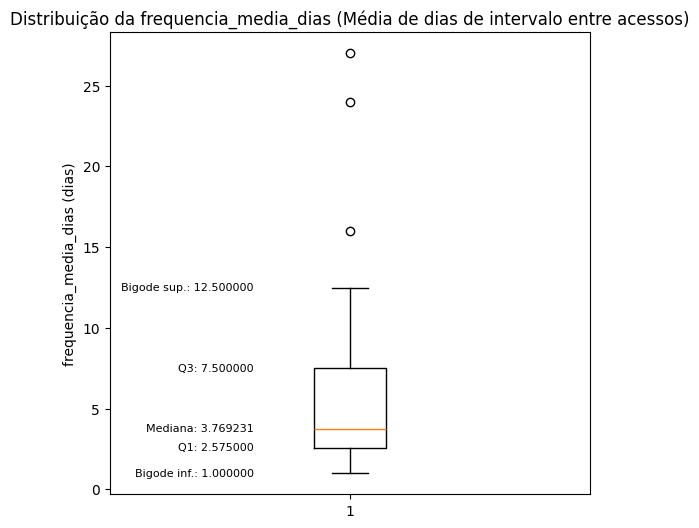

In [0]:
# Boxplot para análise da distribuição da métrica de Frequência (média de dias de intervalo entre acessos) dos alunos pagantes com mais de uma data de acesso - 51 alunos.


import matplotlib.pyplot as plt
import pandas as pd

df_frequencia_media_dias = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_frequencia").toPandas()

df_frequencia_media_dias['frequencia_media_dias'] = pd.to_numeric(
    df_frequencia_media_dias['frequencia_media_dias'], errors='coerce'
)

dados_validos = df_frequencia_media_dias['frequencia_media_dias'].dropna()

fig, ax = plt.subplots(figsize=(8, 6))
plt.subplots_adjust(left=0.3)
bp = ax.boxplot(dados_validos, vert=True)
plt.title('Distribuição da frequencia_media_dias (Média de dias de intervalo entre acessos)')
plt.ylabel('frequencia_media_dias (dias)')
mediana = bp['medians'][0].get_ydata()[0]
q1 = bp['boxes'][0].get_ydata()[0]
q3 = bp['boxes'][0].get_ydata()[2]
bigode_inferior = bp['whiskers'][0].get_ydata()[1]
bigode_superior = bp['whiskers'][1].get_ydata()[1]
for valor, nome in [(mediana, 'Mediana'), (q1, 'Q1'), (q3, 'Q3'),
                     (bigode_inferior, 'Bigode inf.'), (bigode_superior, 'Bigode sup.')]:
    plt.text(0.8, valor, f'{nome}: {valor:.6f}', va='center', ha='right', fontsize=8)
plt.show()

**Interpretação — Distribuição da Frequência (média de dias entre acessos):** Essa análise considera apenas os 51 alunos, que são os que têm pelo menos 2 dias distintos de acesso. Entre esses, metade, cerca de 26 alunos (50% de 51), tem intervalo médio de até 3,77 dias entre acessos (mediana = 3,77), e aproximadamente 13 alunos (25%) têm intervalo médio de 2,58 dias ou menos (Q1 = 2,58). Um segundo grupo, cerca de 13 alunos (25%, entre a mediana e o Q3), tem intervalo médio de 3,77 a 7,5 dias. Já o grupo com ritmo mais espaçado, entre 7,5 e 12,5 dias de intervalo médio (Q3 até o bigode superior = 12,5), reúne cerca de 13 alunos (25%) que em média passam de uma semana entre um acesso e outro. Três alunos aparecem como outliers, com intervalo médio de aproximadamente 16, 24 e 27 dias entre acessos — o ritmo mais espaçado da turma, e que, combinado com poucas datas de acesso, pode indicar tanto baixo engajamento quanto casos pontuais de retomada após um intervalo longo.  Lembrando que como essa média pode ser calculada a partir de apenas 2 datas, um valor baixo aqui não garante engajamento contínuo, só que os acessos registrados (poucos ou muitos) estiveram próximos entre si.

**_Métrica 08 - Progresso e Velocidade do progresso:_** Medir o engajamento macro do aluno na plataforma. O progresso indica o percentual de tempo assistido (limitado a 100% da duração da aula, mas sem percentual mínimo a ser considerado) em relação a toda a carga horária em que ele está matriculado. A velocidade mede o ritmo diário de aprendizado, servindo para identificar "Top Performers" e alertar antecipadamente sobre riscos de evasão, sendo calculado através do Progresso (%) dividido pelo número de dias corridos entre o primeiro acesso a uma aula (qualquer) e a data_fim.

In [0]:
%sql

/* PROGRESSO (%) E VELOCIDADE (% DE PROGRESSO POR DIA) DE CADA ALUNO PAGANTE
Objetivo: 1. Calcular o Progresso (%): tempo assistido (soma por aula, limitado à duração da própria aula) dividido pelo tempo disponível (soma da duração de todas as aulas dos cursos com "Matrícula ativa"). 2. Calcular a Velocidade (% de progresso por dia): Progresso dividido pelos dias corridos entre o primeiro acesso histórico do aluno (menor ultima_visualizacao ou data_conclusao) e data_fim.
Nota 1: cursos 29, 62 e 80 (descontinuados, Validação 6) e 94 (somente agenda) são excluídos do cálculo.
Nota 2: aulas sem correspondência em asn_aulas_duracao não têm duração definida e ficam fora do cálculo.
Nota 3: Progresso e Velocidade usam a mesma base (progresso_total_filtrado sem os cursos excluídos e sem as aulas sem duração). Aluno sem nenhuma linha nessa base tem Progresso e Velocidade NULL (sem dados). Aluno com linha, mesmo com tempo_aula zero ou NA, tem Progresso e Velocidade iguais ou maiores que zero.*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_progresso_velocidade AS
WITH base AS (
    SELECT
        p.aluno_id, p.curso_id, p.aula_id,
        p.ultima_visualizacao, p.data_conclusao, p.tempo_aula,
        d.duracao_segundos
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado p
    JOIN proj_ead.tabelas_metricas_aluno.asn_aulas_duracao d ON p.curso_id = d.curso_id AND p.aula_id = d.aula_id
    WHERE p.curso_id NOT IN (94, 29, 62, 80)
),
tempo_disponivel AS (
    SELECT
        a.aluno_id,
        CAST(SUM(d.duracao_segundos) AS BIGINT) AS tempo_disponivel_segundos
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral a
    JOIN proj_ead.tabelas_metricas_aluno.asn_aulas_duracao d ON a.curso_id = d.curso_id
    WHERE a.status = 'Matrícula ativa'
      AND a.curso_id NOT IN (94, 29, 62, 80)
      AND a.aluno_id IN (SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado)
    GROUP BY a.aluno_id
),
esforco AS (
    WITH tempo_por_aula AS (
        SELECT
            aluno_id, curso_id, aula_id,
            LEAST(
                SUM(COALESCE(
                    TRY_CAST(get(SPLIT(tempo_aula, ':'), 0) AS BIGINT) * 3600 +
                    TRY_CAST(get(SPLIT(tempo_aula, ':'), 1) AS BIGINT) * 60 +
                    TRY_CAST(get(SPLIT(tempo_aula, ':'), 2) AS BIGINT),
                    0
                )),
                MAX(duracao_segundos)
            ) AS tempo_limitado
        FROM base
        GROUP BY aluno_id, curso_id, aula_id
    )
    SELECT aluno_id, CAST(SUM(tempo_limitado) AS BIGINT) AS esforco_segundos
    FROM tempo_por_aula
    GROUP BY aluno_id
),
primeiro_acesso AS (
    SELECT aluno_id, MIN(data_acesso) AS data_inicio
    FROM (
        SELECT aluno_id, DATE(ultima_visualizacao) AS data_acesso
        FROM base WHERE ultima_visualizacao IS NOT NULL
        UNION
        SELECT aluno_id, DATE(TRY_CAST(data_conclusao AS TIMESTAMP)) AS data_acesso
        FROM base WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL
    ) t
    GROUP BY aluno_id
)
SELECT
    t.aluno_id,
    CASE
        WHEN e.aluno_id IS NULL THEN NULL
        ELSE CAST((e.esforco_segundos * 100.0 / td.tempo_disponivel_segundos) AS DECIMAL(18,6))
    END AS progresso,
    CASE
        WHEN e.aluno_id IS NULL THEN NULL
        ELSE CAST((e.esforco_segundos * 100.0 / td.tempo_disponivel_segundos) / GREATEST(DATEDIFF(DATE(:data_fim), p.data_inicio), 1)
        AS DECIMAL(18,6))
    END AS velocidade
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN tempo_disponivel td ON t.aluno_id = td.aluno_id
LEFT JOIN esforco e ON t.aluno_id = e.aluno_id
LEFT JOIN primeiro_acesso p ON t.aluno_id = p.aluno_id
ORDER BY t.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_progresso_velocidade LIMIT 70;

aluno_id,progresso,velocidade
207,null,null
428,0.000000,0.000000
769,2.198777,0.037267
784,null,null
882,1.491104,0.026160
1033,2.096368,0.035532
1078,null,null
1079,0.313450,0.004678
1080,3.366974,0.049514
1083,0.000029,0.000000


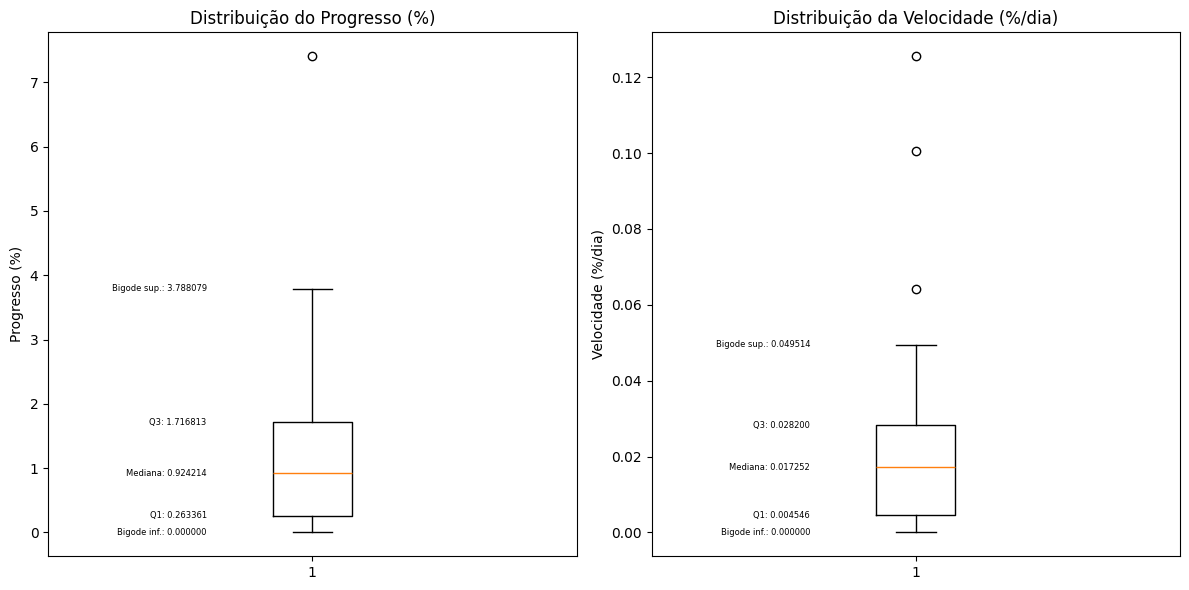

In [0]:
# Boxplot para análise da distribuição do Progresso (%) e da Velocidade (%/dia) - 56 alunos pagantes.

import matplotlib.pyplot as plt
import pandas as pd

df_pv = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_progresso_velocidade").toPandas()
df_pv['progresso'] = pd.to_numeric(df_pv['progresso'], errors='coerce')
df_pv['velocidade'] = pd.to_numeric(df_pv['velocidade'], errors='coerce')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, coluna, titulo, unidade in [
    (axes[0], 'progresso', 'Distribuição do Progresso (%)', 'Progresso (%)'),
    (axes[1], 'velocidade', 'Distribuição da Velocidade (%/dia)', 'Velocidade (%/dia)')
]:
    dados_validos = df_pv[coluna].dropna()
    bp = ax.boxplot(dados_validos, vert=True)
    ax.set_title(titulo)
    ax.set_ylabel(unidade)
    mediana = bp['medians'][0].get_ydata()[0]
    q1 = bp['boxes'][0].get_ydata()[0]
    q3 = bp['boxes'][0].get_ydata()[2]
    bigode_inferior = bp['whiskers'][0].get_ydata()[1]
    bigode_superior = bp['whiskers'][1].get_ydata()[1]
    for valor, nome in [(mediana, 'Mediana'), (q1, 'Q1'), (q3, 'Q3'),
                         (bigode_inferior, 'Bigode inf.'), (bigode_superior, 'Bigode sup.')]:
        ax.text(0.8, valor, f'{nome}: {valor:.6f}', va='center', ha='right', fontsize=6)
plt.tight_layout()
plt.show()

**Interpretação — Distribuição do Progresso (%):** Essa análise considera os 56 alunos pagantes com registro de acesso a aulas válidas. Os valores de Progresso são baixos em toda a base: metade, cerca de 28 alunos (50%), tem no máximo 0,92% da carga horária assistida (mediana = 0,92), e 25% (cerca de 14 alunos) não passa de 0,26% (Q1 = 0,26). Outro grupo de 14 alunos (25%, entre mediana e Q3) vai de 0,92% a 1,72% (Q3 = 1,72). Os alunos com maior avanço, cerca de 14 alunos (25%), estão entre 1,72% e 3,79% (Q3 até o bigode superior). Um aluno se destaca como outlier, com 7,41% da carga horária assistida, bem acima do restante da turma, embora ainda distante da conclusão dos cursos.

**Interpretação — Distribuição da Velocidade (%/dia):** Essa análise considera os mesmos 56 alunos do Progresso. O ritmo de avanço é, de forma geral, bem baixo: metade, cerca de 28 alunos (50%), progride no máximo 0,017%/dia (mediana = 0,017), e 25% (cerca de 14 alunos) não passa de 0,0045%/dia (Q1 = 0,0045). Outro grupo de 14 alunos (25%, entre mediana e Q3) vai de 0,017%/dia a 0,028%/dia (Q3 = 0,028). Os alunos com ritmo mais rápido, cerca de 14 alunos (25%), estão entre 0,028%/dia e 0,0495%/dia (Q3 até o bigode superior). Três alunos aparecem como outliers, com velocidade de aproximadamente 0,064%/dia, 0,100%/dia e 0,125%/dia, um ritmo de avanço bem mais acelerado que o da turma.

**_Métrica 11 - Cursos Concluídos e Cursos Em Andamento:_** Medir em quantos cursos o aluno chegou ao mínimo para emissão de certificado (75%) e em quantos está avançando, ou seja, cursos abaixo de 75% com pelo menos uma aula assistida (mínimo conforme percentual_minimo_assistido). Cursos só com cliques não entram em nenhuma contagem.

In [0]:
%sql

/* CURSOS CONCLUÍDOS E CURSOS EM ANDAMENTO DE CADA ALUNO PAGANTE
Objetivo: Contar, por aluno, os cursos concluídos (tempo assistido >= 75% da duração total do curso, mesmo patamar de liberação do certificado) e os cursos em andamento (abaixo de 75%, com pelo menos uma aula assistida, ou seja, tempo_aula / duracao_segundos >= percentual_minimo_assistido). O tempo de cada aula é limitado à duração da própria aula e a duração total do curso considera todas as aulas de asn_aulas_duracao.
Nota 1: cursos 29, 62, 80 e 94 e aulas sem correspondência em asn_aulas_duracao ficam fora do cálculo, como em Progresso e Velocidade.
Nota 2: curso com apenas cliques (abaixo de 75% e sem aula assistida) não entra em nenhuma das contagens.
Nota 3: aluno sem nenhuma linha na base tem as duas colunas NULL (sem dados). Aluno com linha, mas sem curso contado, tem as duas colunas iguais a zero.*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_cursos AS
WITH base AS (
    SELECT
        p.aluno_id, p.curso_id, p.aula_id,
        p.tempo_aula, d.duracao_segundos
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado p
    JOIN proj_ead.tabelas_metricas_aluno.asn_aulas_duracao d ON p.curso_id = d.curso_id AND p.aula_id = d.aula_id
    WHERE p.curso_id NOT IN (94, 29, 62, 80)
),
tempo_por_aula AS (
    SELECT
        aluno_id, curso_id, aula_id,
        LEAST(
            SUM(COALESCE(
                TRY_CAST(get(SPLIT(tempo_aula, ':'), 0) AS BIGINT) * 3600 +
                TRY_CAST(get(SPLIT(tempo_aula, ':'), 1) AS BIGINT) * 60 +
                TRY_CAST(get(SPLIT(tempo_aula, ':'), 2) AS BIGINT),
                0
            )),
            MAX(duracao_segundos)
        ) AS tempo_limitado,
        MAX(duracao_segundos) AS duracao_aula
    FROM base
    GROUP BY aluno_id, curso_id, aula_id
),
duracao_curso AS (
    SELECT curso_id, CAST(SUM(duracao_segundos) AS BIGINT) AS duracao_curso_segundos
    FROM proj_ead.tabelas_metricas_aluno.asn_aulas_duracao
    GROUP BY curso_id
),
por_curso AS (
    SELECT
        t.aluno_id, t.curso_id,
        SUM(t.tempo_limitado) AS tempo_curso,
        MAX(CASE WHEN t.duracao_aula > 0
                  AND t.tempo_limitado * 1.0 / t.duracao_aula >= CAST(:percentual_minimo_assistido AS DOUBLE)
                 THEN 1 ELSE 0 END) AS tem_aula_assistida,
        MAX(c.duracao_curso_segundos) AS duracao_curso_segundos
    FROM tempo_por_aula t
    JOIN duracao_curso c ON t.curso_id = c.curso_id
    GROUP BY t.aluno_id, t.curso_id
),
classificacao AS (
    SELECT
        aluno_id,
        CASE WHEN duracao_curso_segundos > 0
              AND tempo_curso * 1.0 / duracao_curso_segundos >= 0.75 THEN 1 ELSE 0 END AS concluido,
        CASE WHEN NOT (duracao_curso_segundos > 0
                       AND tempo_curso * 1.0 / duracao_curso_segundos >= 0.75)
              AND tem_aula_assistida = 1 THEN 1 ELSE 0 END AS em_andamento
    FROM por_curso
),
contagem AS (
    SELECT
        aluno_id,
        SUM(concluido) AS cursos_concluidos,
        SUM(em_andamento) AS cursos_andamento
    FROM classificacao
    GROUP BY aluno_id
)
SELECT
    t.aluno_id,
    CAST(c.cursos_concluidos AS INT) AS cursos_concluidos,
    CAST(c.cursos_andamento AS INT) AS cursos_andamento
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN contagem c ON t.aluno_id = c.aluno_id
ORDER BY t.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_cursos LIMIT 70;

aluno_id,cursos_concluidos,cursos_andamento
207,null,null
428,0,0
769,0,1
784,null,null
882,1,2
1033,0,1
1078,null,null
1079,0,1
1080,1,8
1083,0,0


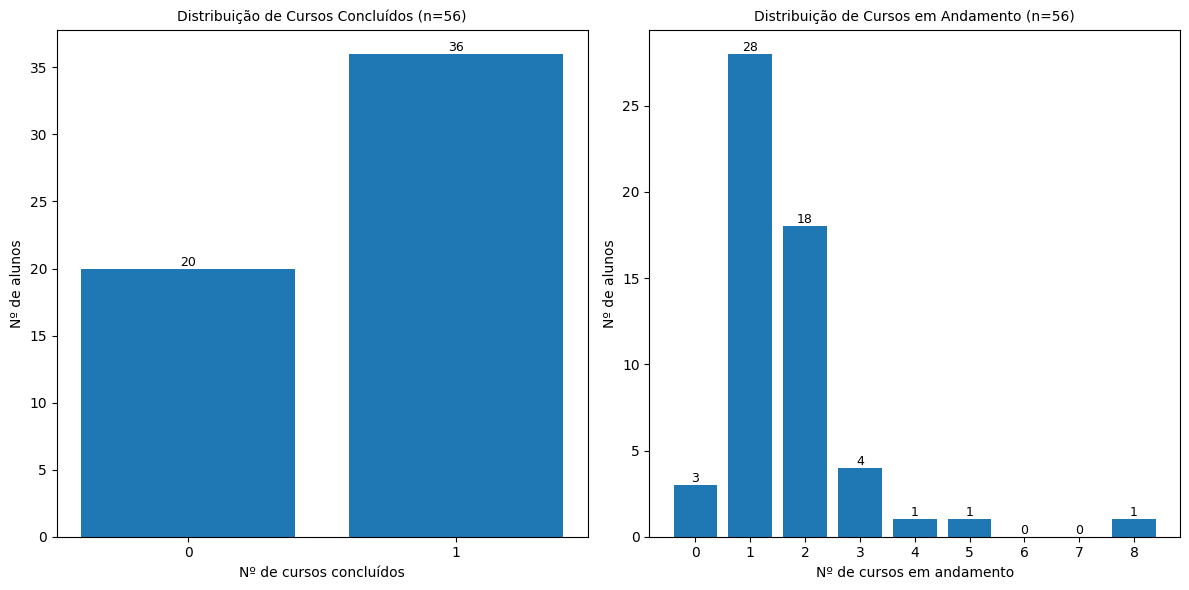

In [0]:
# Gráfico de barras para análise da distribuição de Cursos Concluídos e Cursos em Andamento dos 56 alunos pagantes com pelo menos uma linha em aulas válidas.

import matplotlib.pyplot as plt
import pandas as pd

df_cursos = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_cursos").toPandas()
df_cursos['cursos_concluidos'] = pd.to_numeric(df_cursos['cursos_concluidos'], errors='coerce')
df_cursos['cursos_andamento'] = pd.to_numeric(df_cursos['cursos_andamento'], errors='coerce')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, coluna, titulo, rotulo_x in [
    (axes[0], 'cursos_concluidos', 'Distribuição de Cursos Concluídos', 'Nº de cursos concluídos'),
    (axes[1], 'cursos_andamento', 'Distribuição de Cursos em Andamento', 'Nº de cursos em andamento')
]:
    dados_validos = df_cursos[coluna].dropna().astype(int)
    frequencia = dados_validos.value_counts().sort_index()
    frequencia = frequencia.reindex(range(0, frequencia.index.max() + 1), fill_value=0)
    barras = ax.bar(frequencia.index.astype(str), frequencia.values)
    ax.bar_label(barras, fontsize=9)
    ax.set_title(f'{titulo} (n={len(dados_validos)})', fontsize=10)
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel('Nº de alunos')
plt.tight_layout()
plt.show()

**Interpretação — Distribuição de Cursos Concluídos e Cursos em Andamento:** Essa análise considera 56 alunos pagantes. Em Cursos Concluídos, 36 alunos (64%) concluíram 1 curso e 20 (36%) não concluíram nenhum; nenhum aluno concluiu mais de um. Em Cursos em Andamento, a maior parte está em 1 ou 2 cursos: 28 alunos (50%) têm 1 curso em andamento e 18 (32%) têm 2. Outros 4 alunos têm 3 cursos, 3 alunos não têm nenhum curso em andamento, e há casos isolados com 4, 5 e 8 cursos (1 aluno em cada), sendo o de 8 cursos o que mais se destaca. Lembrando que para a contagem de cursos concluídos, considera-se o aluno ter atingido no mínimo 75% do tempo de duração do curso, e para cursos em andamento, são contabilizados os que têm no mínimo 1 aula assistida, ou seja, com pelo menos o percentual_minimo_assistido da duração da aula. 


**_Métrica 06 - Histórico de número de acessos:_** Analisar o comportamento dos acessos do aluno na plataforma ao longo do período. Uso de cálculo de slope para substituir numericamente representação por gráfico

In [0]:
%sql

/* TENDÊNCIA DE ACESSOS (SLOPE) DE CADA ALUNO PAGANTE, COM R² (CONFIABILIDADE DA TENDÊNCIA)
Objetivo: 1. Calcular a métrica que indica a tendência do histórico de acessos, definida como o slope (regressão linear) do número de acessos por período. 2. Calcular o R² dessa mesma regressão, que mede o quanto os pontos realmente seguem a tendência (0 a 1): perto de 1, a tendência é confiável; perto de 0, os pontos oscilam e o slope não representa bem o comportamento real. 3. O tamanho do período é ajustável por parâmetro manual. 4. O número de períodos é calculado entre a data de início (maior valor entre data_inicio e a data de matrícula do aluno) e a data_fim. Nota: Alunos pagantes sem nenhum registro em progresso_total_filtrado, ou com menos de 2 datas de acesso, recebem valor NULL em ambas as colunas (Validação 3). */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.metrica_historico AS
WITH data_matricula_aluno AS (
    SELECT
        ag.aluno_id,
        GREATEST(DATE(:data_inicio), MAX(DATE(TRY_CAST(a.cadastro AS TIMESTAMP)))) AS data_matricula
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado ag
    JOIN proj_ead.tabelas_metricas_aluno.alunos_geral a ON ag.aluno_id = a.aluno_id
    WHERE TRY_CAST(a.cadastro AS TIMESTAMP) IS NOT NULL
    GROUP BY ag.aluno_id
),
datas_acesso AS (
    SELECT 
        aluno_id, 
        DATE(ultima_visualizacao) AS data_acesso
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
    WHERE ultima_visualizacao IS NOT NULL
    UNION
    SELECT 
        aluno_id, 
        DATE(TRY_CAST(data_conclusao AS TIMESTAMP)) AS data_acesso
    FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
    WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL
),
datas_unicas AS (
    SELECT DISTINCT 
        aluno_id, 
        data_acesso 
    FROM datas_acesso
),
qtd_datas_reais AS (
    SELECT aluno_id, COUNT(*) AS qtd_datas_distintas
    FROM datas_unicas
    GROUP BY aluno_id
),
acessos_com_periodo AS (
    SELECT
        d.aluno_id,
        d.data_acesso,
        CAST(FLOOR(DATEDIFF(d.data_acesso, m.data_matricula) / CAST(:tamanho_periodo AS DOUBLE)) AS INT) + 1 AS periodo
    FROM datas_unicas d
    JOIN data_matricula_aluno m ON d.aluno_id = m.aluno_id
    WHERE d.data_acesso >= m.data_matricula
),
contagem_por_periodo AS (
    SELECT aluno_id, periodo, COUNT(*) AS acessos
    FROM acessos_com_periodo
    GROUP BY aluno_id, periodo
),
total_periodos AS (
    SELECT
        m.aluno_id,
        CAST(CEIL((DATEDIFF(DATE(:data_fim), m.data_matricula) + 1) / CAST(:tamanho_periodo AS DOUBLE)) AS INT) AS max_periodo
    FROM data_matricula_aluno m
),
grade_periodos AS (
    SELECT t.aluno_id, gs AS periodo
    FROM total_periodos t
    LATERAL VIEW explode(sequence(1, t.max_periodo)) AS gs
),
grade_com_acessos AS (
    SELECT
        g.aluno_id,
        g.periodo,
        COALESCE(c.acessos, 0) AS acessos
    FROM grade_periodos g
    LEFT JOIN contagem_por_periodo c
        ON g.aluno_id = c.aluno_id AND g.periodo = c.periodo
),
slope_calc AS (
    SELECT
        aluno_id,
        regr_slope(acessos, periodo) AS slope,
        regr_r2(acessos, periodo) AS r2
    FROM grade_com_acessos
    GROUP BY aluno_id
)
SELECT
    t.aluno_id,
    CASE
        WHEN q.qtd_datas_distintas IS NULL OR q.qtd_datas_distintas < 2 THEN NULL
        ELSE CAST(s.slope AS DECIMAL(18,6))
    END AS tendencia_acessos,
    CASE
        WHEN q.qtd_datas_distintas IS NULL OR q.qtd_datas_distintas < 2 THEN NULL
        ELSE CAST(s.r2 AS DECIMAL(18,6))
    END AS r2_hist_acessos
FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
LEFT JOIN qtd_datas_reais q ON t.aluno_id = q.aluno_id
LEFT JOIN slope_calc s ON t.aluno_id = s.aluno_id
ORDER BY t.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_historico LIMIT 70;

aluno_id,tendencia_acessos,r2_hist_acessos
207,null,null
428,null,null
769,-0.371429,0.254135
784,null,null
882,-0.714286,0.601926
1033,-0.828571,0.471148
1078,null,null
1079,-0.392857,0.102891
1080,-0.392857,0.094531
1083,-0.142857,0.117647


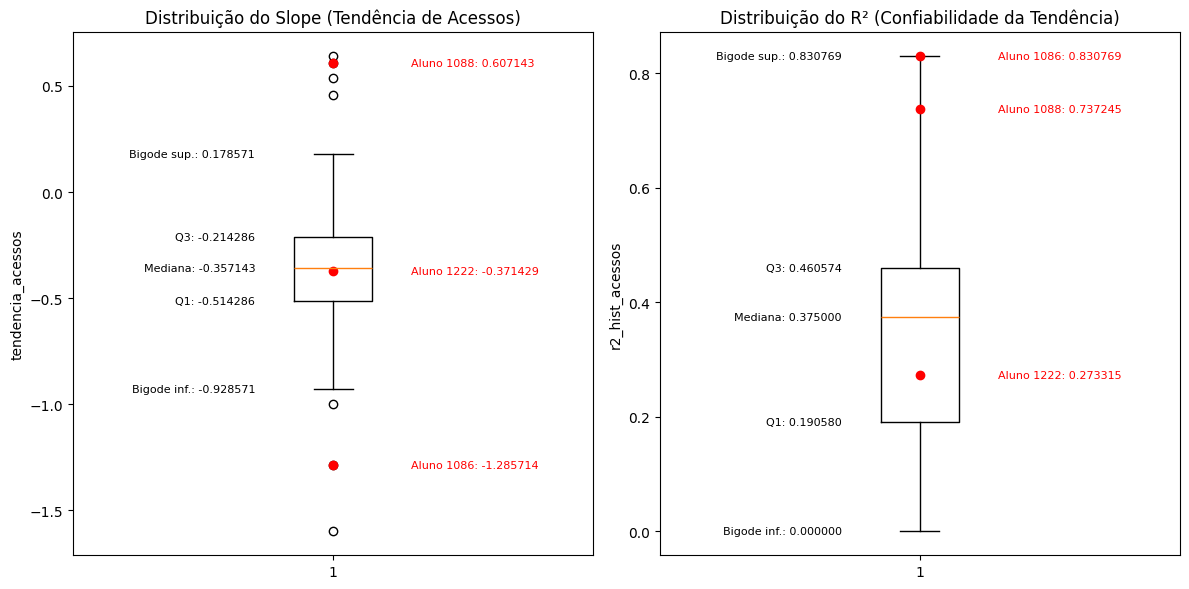

In [0]:
# Boxplot para análise da distribuição do histórico de número de acessos através do cálculo de slope (regressão linear) e do R² (confiabilidade dessa tendência) dos alunos pagantes (51) com mais de um acesso, destacando 3 alunos específicos - 1086, 1088, 1222. A mudança nos parâmetros aluno_1, aluno_2 e aluno_3 NÃO altera esse gráfico.

import matplotlib.pyplot as plt
import pandas as pd

df_slope = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.metrica_historico").toPandas()
df_slope['tendencia_acessos'] = pd.to_numeric(df_slope['tendencia_acessos'], errors='coerce')
df_slope['r2_hist_acessos'] = pd.to_numeric(df_slope['r2_hist_acessos'], errors='coerce')

alunos_destaque = [1086, 1088, 1222]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, coluna, titulo in [
    (axes[0], 'tendencia_acessos', 'Distribuição do Slope (Tendência de Acessos)'),
    (axes[1], 'r2_hist_acessos', 'Distribuição do R² (Confiabilidade da Tendência)')
]:
    dados_validos = df_slope[coluna].dropna()
    bp = ax.boxplot(dados_validos, vert=True)
    ax.set_title(titulo)
    ax.set_ylabel(coluna)
    mediana = bp['medians'][0].get_ydata()[0]
    q1 = bp['boxes'][0].get_ydata()[0]
    q3 = bp['boxes'][0].get_ydata()[2]
    bigode_inferior = bp['whiskers'][0].get_ydata()[1]
    bigode_superior = bp['whiskers'][1].get_ydata()[1]
    for valor, nome in [(mediana, 'Mediana'), (q1, 'Q1'), (q3, 'Q3'),
                         (bigode_inferior, 'Bigode inf.'), (bigode_superior, 'Bigode sup.')]:
        ax.text(0.85, valor, f'{nome}: {valor:.6f}', va='center', ha='right', fontsize=8)

    for aluno_id in alunos_destaque:
        linha = df_slope[df_slope['aluno_id'] == aluno_id]
        if linha.empty:
            continue
        valor = linha[coluna].iloc[0]
        if pd.isna(valor):
            continue
        ax.plot(1, valor, 'ro', markersize=6)
        ax.text(1.15, valor, f'Aluno {aluno_id}: {valor:.6f}', va='center', ha='left', fontsize=8, color='red')

plt.tight_layout()
plt.show()

**Sobre a leitura conjunta de Slope e R²:** O slope mostra a direção da tendência, o R² complementa essa leitura, indicando o quanto ela é confiável ou se está influenciada por pontos fora do padrão. Assim, slope alto com R² alto indica tendência forte e real; slope alto com R² baixo sugere que a tendência pode estar distorcida por poucos pontos fora do padrão; slope baixo com R² alto indica estabilidade real; e slope baixo com R² baixo não é estabilidade, é oscilação, mesmo que a média dê um resultado próximo de zero. Lembrando:

Para Distribuição do Slope - Tendência de Acessos - valores negativos indicam tendência de queda no ritmo de acessos ao longo do período analisado; positivos, tendência de crescimento, próximo a zero possível estabilidade.

Para Distribuição de R2 - Confiabilidade da Tendência - valores próximos de 1 indicam que a tendência do slope é confiável (os acessos seguem de perto a reta calculada); valores próximos de 0 indicam que os pontos estão dispersos, e o slope não representa bem o comportamento real do aluno.

Ressalva: o R² não diz se a tendência é boa ou ruim para o aluno, só se ela é confiável. Um R² baixo não invalida o slope, mas indica que ele deve ser lido com mais cautela — o comportamento real pode estar mais próximo de uma oscilação do que de uma tendência linear consistente.

Abaixo segue análise dos gráficos considerando os 51 alunos com dados suficientes para o cálculo.

**Interpretação — Distribuição do Slope (Tendência de Acessos):** A maior parte da turma apresenta tendência de queda: metade, cerca de 26 alunos (50%), tem slope de até -0,357 (mediana), e 25% (13 alunos) apresentam queda mais acentuada dentro do período, com slope de -0,514 ou menos (Q1). Outro grupo de 13 alunos (25%, entre mediana e Q3) tem queda mais leve dentro do período, entre -0,357 e -0,214. Já os 13 alunos (25%) entre -0,214 e 0,179 (Q3 ao bigode superior) são o único grupo com tendência estável ou de leve crescimento dentro do período. Nos extremos: três alunos com tendência de queda mais acentuada (outliers próximos de -1,0 e -1,6, próximos do destacado 1086, slope -1,286). Quatro outros, com tendência de crescimento mais acentuada (outliers acima de 0,45, próximos do destacado 1088, slope 0,607). O aluno 1222 (slope -0,371) está próximo da tendência típica da maioria. Ressalva: por representar a tendência ao longo de todo o período analisado, o slope não captura necessariamente o comportamento mais recente do aluno — uma queda ao longo do período pode conter uma recuperação nos últimos ciclos, assim como uma tendência de crescimento pode mascarar uma queda recente.

**Interpretação — Distribuição do R² (Confiabilidade da Tendência):** De forma geral, a confiabilidade das tendências é baixa a moderada: metade, cerca de 26 alunos (50%), tem R² de até 0,375 (mediana), e 25% (13 alunos) têm R² ainda mais baixo, de 0,191 ou menos (Q1) — ou seja, para boa parte da turma, o slope calculado tem pouca aderência ao padrão real de acessos. Outro grupo de 13 alunos (25%, entre mediana e Q3) tem R² entre 0,375 e 0,461. Já os 13 alunos (25%) entre 0,461 e 0,831 (Q3 ao bigode superior) são o grupo com tendências mais confiáveis, sem nenhum outlier acima do bigode superior. Os três alunos destacados mostram justamente a utilidade de olhar R² junto do slope: o aluno 1086 (R² = 0,831, no limite superior da distribuição) tem uma das quedas mais acentuadas da base e também a tendência mais confiável — a queda é real e consistente, não ruído. O aluno 1088 (R² = 0,737) também tem confiabilidade alta, reforçando que seu crescimento (slope 0,607) é uma tendência genuína. Já o aluno 1222 (R² = 0,273, entre mediana e Q1) tem confiabilidade baixa — sua queda de slope (-0,371) é bem menos sustentada que a dos outros dois, sugerindo que os acessos dele oscilam mais do que a reta de tendência consegue captar.

**_Métrica 09 - Evolução Mensal:_** Medir a linha do tempo e a sazonalidade do esforço do aluno. O objetivo é entender o comportamento mês a mês (se ele está acelerando, mantendo o ritmo ou abandonando os estudos), visualizando a quantidade de conteúdo consumido e o tempo real dedicado naquele período.



In [0]:
%sql

/* GERAÇÃO DE progresso_evolucao_mensal 
Objetivo: 1. Criar uma base derivada de progresso_total_filtrado, específica para a métrica de Evolução Mensal, excluindo os cursos 94 (somente agenda), 29, 62 e 80 (descontinuados, sem duração cadastrada em asn_aulas_duracao). O status de matrícula ativa já está garantido em progresso_total_filtrado.*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.progresso_evolucao_mensal AS
SELECT p.*
FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado p
WHERE p.curso_id NOT IN (94, 29, 62, 80);

SELECT * FROM proj_ead.tabelas_metricas_aluno.progresso_evolucao_mensal LIMIT 10;

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,tempo_aula,data_conclusao,aula_concluido,_rescued_data,ultima_visualizacao
217,20,IDA,217,1118,O que é probabilidade?,1215,00:20:41,2026-01-09T19:41:10Z,1,null,2026-01-09T19:57:25.000
217,20,IDA,217,1118,O que é probabilidade?,1201,00:29:14,2025-12-09T18:13:35Z,1,null,2025-12-28T21:03:50.000
217,20,IDA,217,1118,O que é probabilidade?,1195,00:16:53,2025-12-21T01:58:57Z,1,null,2026-01-14T11:04:14.000
217,20,IDA,217,1118,O que é probabilidade?,1224,00:16:39,2026-01-06T19:22:41Z,1,null,2026-01-11T16:15:57.000
217,20,IDA,217,1118,O que é probabilidade?,1213,00:14:48,2026-01-06T11:36:58Z,1,null,2026-01-07T08:46:31.000
217,20,IDA,217,1118,O que é probabilidade?,1090,00:16:01,2025-11-24T14:55:22Z,1,null,2025-11-24T15:10:35.000
217,20,IDA,217,1118,O que é probabilidade?,1080,00:15:35,2025-11-23T23:22:10Z,1,null,2025-11-23T23:35:51.000
217,20,IDA,217,1119,Distribuição Estatística,1215,00:43:40,2026-01-09T20:15:01Z,1,null,2026-01-09T20:38:15.000
217,20,IDA,217,1119,Distribuição Estatística,1201,01:54:06,2025-12-09T18:31:37Z,1,null,2025-12-28T21:50:19.000
217,20,IDA,217,1119,Distribuição Estatística,1195,00:44:57,2026-01-11T13:13:50Z,1,null,2026-01-14T11:08:50.000


In [0]:
%sql

/* GERAÇÃO DE progresso_com_percentual, COM O PERCENTUAL ASSISTIDO E A MARCAÇÃO DE AULA_ASSISTIDA PARA CADA REGISTRO
Objetivo: 1. Calcular o percentual assistido de cada aula (tempo_aula / duracao_segundos) e marcar como "aula_assistida" quando esse percentual é maior ou igual ao parâmetro percentual_minimo_assistido, usado no cálculo de Volume para distinguir acesso real de apenas abertura/clique. 2. Converter tempo_aula (formato hh:mm:ss, texto) para segundos antes do cálculo. 
Nota 1: valores não numéricos para tempo_aula (ex.: 'NA') viram nulo, e a aula é tratada como não assistida. 
Nota 2: Aulas sem correspondência em asn_aulas_duracao (ver validação 7) não são incluídas no cálculo de Volume, por falta de duração para calcular o percentual, subestimando o resultado para quem acessou essas aulas. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.progresso_com_percentual AS
SELECT
    p.*,
    d.duracao_segundos,
    (TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 1) AS INTEGER) * 3600
        + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 2) AS INTEGER) * 60
        + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 3) AS INTEGER)) AS tempo_aula_segundos,
    CASE
        WHEN d.duracao_segundos IS NULL OR d.duracao_segundos = 0 THEN NULL
        WHEN TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 1) AS INTEGER) IS NULL THEN NULL
        ELSE (TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 1) AS INTEGER) * 3600
                + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 2) AS INTEGER) * 60
                + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 3) AS INTEGER)) / d.duracao_segundos
    END AS percentual_assistido,
    CASE
        WHEN d.duracao_segundos IS NULL OR d.duracao_segundos = 0 THEN FALSE
        WHEN TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 1) AS INTEGER) IS NULL THEN FALSE
        WHEN (TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 1) AS INTEGER) * 3600
                + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 2) AS INTEGER) * 60
                + TRY_CAST(SPLIT_PART(p.tempo_aula, ':', 3) AS INTEGER)) / d.duracao_segundos
             >= CAST(:percentual_minimo_assistido AS DOUBLE) THEN TRUE
        ELSE FALSE
    END AS aula_assistida
FROM proj_ead.tabelas_metricas_aluno.progresso_evolucao_mensal p
LEFT JOIN proj_ead.tabelas_metricas_aluno.asn_aulas_duracao d
    ON p.curso_id = d.curso_id
    AND p.aula_id = d.aula_id;
SELECT * FROM proj_ead.tabelas_metricas_aluno.progresso_com_percentual LIMIT 10;

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,tempo_aula,data_conclusao,aula_concluido,_rescued_data,ultima_visualizacao,duracao_segundos,tempo_aula_segundos,percentual_assistido,aula_assistida
217,20,IDA,217,1118,O que é probabilidade?,1215,00:20:41,2026-01-09T19:41:10Z,1,null,2026-01-09T19:57:25.000,877.0,1241,1.4150513112884835,true
217,20,IDA,217,1118,O que é probabilidade?,1201,00:29:14,2025-12-09T18:13:35Z,1,null,2025-12-28T21:03:50.000,877.0,1754,2.0,true
217,20,IDA,217,1118,O que é probabilidade?,1195,00:16:53,2025-12-21T01:58:57Z,1,null,2026-01-14T11:04:14.000,877.0,1013,1.1550741163055873,true
217,20,IDA,217,1118,O que é probabilidade?,1224,00:16:39,2026-01-06T19:22:41Z,1,null,2026-01-11T16:15:57.000,877.0,999,1.1391106043329533,true
217,20,IDA,217,1118,O que é probabilidade?,1213,00:14:48,2026-01-06T11:36:58Z,1,null,2026-01-07T08:46:31.000,877.0,888,1.0125427594070695,true
217,20,IDA,217,1118,O que é probabilidade?,1090,00:16:01,2025-11-24T14:55:22Z,1,null,2025-11-24T15:10:35.000,877.0,961,1.0957810718358039,true
217,20,IDA,217,1118,O que é probabilidade?,1080,00:15:35,2025-11-23T23:22:10Z,1,null,2025-11-23T23:35:51.000,877.0,935,1.0661345496009123,true
217,20,IDA,217,1119,Distribuição Estatística,1215,00:43:40,2026-01-09T20:15:01Z,1,null,2026-01-09T20:38:15.000,2629.0,2620,0.99657664511221,true
217,20,IDA,217,1119,Distribuição Estatística,1201,01:54:06,2025-12-09T18:31:37Z,1,null,2025-12-28T21:50:19.000,2629.0,6846,2.604031951312286,true
217,20,IDA,217,1119,Distribuição Estatística,1195,00:44:57,2026-01-11T13:13:50Z,1,null,2026-01-14T11:08:50.000,2629.0,2697,1.0258653480410802,true


In [0]:
%sql

/* REGISTROS DE ATIVIDADE MENSAL (ALUNO, CURSO, MÓDULO, AULA E MÊS) USADOS NO CÁLCULO DA MÉTRICA DE VOLUME 
Objetivo: 1. Gerar o mes_atividade (Ano-Mês) para o cálculo de Volume, a partir de data_conclusao. 2. Considerar apenas aulas efetivamente assistidas (aula_assistida = TRUE) e com data_conclusao válida. 
Nota 1: Existem aulas com data_conclusao nula, que serão descartadas, com possível impacto tanto em contagem de aula/curso como em tempo (Validação 4). */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.atividade_mensal_volume AS
SELECT DISTINCT
    aluno_id,
    curso_id,
    modulo_id,
    aula_id,
    DATE_FORMAT(DATE(TRY_CAST(data_conclusao AS TIMESTAMP)), 'yyyy-MM') AS mes_atividade
FROM proj_ead.tabelas_metricas_aluno.progresso_com_percentual
WHERE aula_assistida = TRUE
  AND TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL;

SELECT * FROM proj_ead.tabelas_metricas_aluno.atividade_mensal_volume ORDER BY aluno_id, mes_atividade LIMIT 10;

aluno_id,curso_id,modulo_id,aula_id,mes_atividade
769,76,610,4009,2025-12
769,76,610,4010,2025-12
769,76,610,4012,2025-12
769,76,610,4007,2025-12
769,76,595,3929,2025-12
769,76,610,4008,2025-12
769,76,610,4011,2025-12
769,76,610,4016,2026-01
769,76,610,4013,2026-01
769,76,610,4015,2026-01


In [0]:
%sql

/* CONTAGEM DE CURSOS DISTINTOS E AULAS DISTINTAS ASSISTIDAS POR ALUNO E MÊS
Objetivo: 1. Agregar o Esforço em Volume por aluno e mês: contagem de cursos distintos e aulas distintas efetivamente assistidas em cada mes_atividade. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.volume_mensal AS
SELECT
    aluno_id,
    mes_atividade,
    COUNT(DISTINCT curso_id) AS cursos_distintos,
    COUNT(DISTINCT aula_id) AS aulas_distintas
FROM proj_ead.tabelas_metricas_aluno.atividade_mensal_volume
GROUP BY aluno_id, mes_atividade
ORDER BY aluno_id, mes_atividade;

SELECT * FROM proj_ead.tabelas_metricas_aluno.volume_mensal LIMIT 10;

aluno_id,mes_atividade,cursos_distintos,aulas_distintas
769,2025-12,1,7
769,2026-01,1,4
882,2025-11,1,10
882,2025-12,2,8
1033,2025-12,1,13
1079,2025-11,1,6
1079,2025-12,1,19
1080,2025-11,9,79
1080,2025-12,2,14
1080,2026-01,2,6


In [0]:
%sql

/* TAXA DE CURSOS DISTINTOS E DE AULAS DISTINTAS POR DIA DISPONÍVEL, PARA CADA ALUNO PAGANTE E MÊS, COM NULO NOS MESES SEM ACESSO E 0 NOS MESES COM ACESSO ABAIXO DO MÍNIMO. 
Objetivo: 1. Gerar a grade completa de aluno pagante × mês para o Esforço em Volume, calculando cursos/aulas distintas por dia disponível no mês (taxa), em vez de um valor absoluto — evitando distorção em meses parciais.  
Nota 1: Alunos sem nenhum registro de acesso no mês (nenhuma aula com data_conclusao válida naquele mês) recebem valor NULL para aquele mês.
Nota 2: Alunos com registro de acesso, mas sem nenhuma aula atingindo o percentual mínimo assistido, recebem valor zero, há dado, mas não suficiente para contar como aula/curso efetivamente assistido.*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.volume_final AS
WITH data_matricula_aluno AS (
    SELECT
        aluno_id,
        GREATEST(DATE(:data_inicio), MAX(DATE(TRY_CAST(cadastro AS TIMESTAMP)))) AS data_matricula
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral
    WHERE aluno_id IN (SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado)
      AND TRY_CAST(cadastro AS TIMESTAMP) IS NOT NULL
    GROUP BY aluno_id
),
periodo_aluno AS (
    SELECT
        t.aluno_id,
        m.data_matricula,
        CAST(
            (YEAR(DATE(:data_fim)) - YEAR(m.data_matricula)) * 12
            + (MONTH(DATE(:data_fim)) - MONTH(m.data_matricula))
        AS INT) + 1 AS qtd_meses
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
    JOIN data_matricula_aluno m ON t.aluno_id = m.aluno_id
),
grade_meses AS (
    SELECT
        p.aluno_id,
        p.data_matricula,
        CAST(DATE_TRUNC('MONTH', ADD_MONTHS(p.data_matricula, i)) AS DATE) AS inicio_mes,
        DATE_FORMAT(ADD_MONTHS(p.data_matricula, i), 'yyyy-MM') AS mes_atividade
    FROM periodo_aluno p
    LATERAL VIEW explode(sequence(0, p.qtd_meses - 1)) AS i
),
grade_com_dias AS (
    SELECT
        g.aluno_id,
        g.mes_atividade,
        DATEDIFF(
            LEAST(LAST_DAY(g.inicio_mes), DATE(:data_fim)),
            GREATEST(g.inicio_mes, g.data_matricula)
        ) + 1 AS dias_com_dados_no_mes
    FROM grade_meses g
),
acesso_mensal AS (
    SELECT DISTINCT
        aluno_id,
        DATE_FORMAT(DATE(TRY_CAST(data_conclusao AS TIMESTAMP)), 'yyyy-MM') AS mes_atividade
    FROM proj_ead.tabelas_metricas_aluno.progresso_com_percentual
    WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL
)
SELECT
    g.aluno_id,
    g.mes_atividade,
    CASE
        WHEN a.aluno_id IS NULL THEN NULL
        WHEN v.cursos_distintos IS NULL THEN CAST(0 AS DECIMAL(18,6))
        ELSE CAST(CAST(v.cursos_distintos AS DOUBLE) / g.dias_com_dados_no_mes AS DECIMAL(18,6))
    END AS cursos_distintos_taxa,
    CASE
        WHEN a.aluno_id IS NULL THEN NULL
        WHEN v.aulas_distintas IS NULL THEN CAST(0 AS DECIMAL(18,6))
        ELSE CAST(CAST(v.aulas_distintas AS DOUBLE) / g.dias_com_dados_no_mes AS DECIMAL(18,6))
    END AS aulas_distintas_taxa
FROM grade_com_dias g
LEFT JOIN proj_ead.tabelas_metricas_aluno.volume_mensal v ON g.aluno_id = v.aluno_id AND g.mes_atividade = v.mes_atividade
LEFT JOIN acesso_mensal a ON g.aluno_id = a.aluno_id AND g.mes_atividade = a.mes_atividade
ORDER BY g.aluno_id, g.mes_atividade;

SELECT * FROM proj_ead.tabelas_metricas_aluno.volume_final LIMIT 10;

aluno_id,mes_atividade,cursos_distintos_taxa,aulas_distintas_taxa
207,2025-11,null,null
207,2025-12,null,null
207,2026-01,null,null
428,2025-11,null,null
428,2025-12,null,null
428,2026-01,0.000000,0.000000
769,2025-11,0.000000,0.000000
769,2025-12,0.032258,0.225806
769,2026-01,0.038462,0.153846
784,2025-11,null,null


In [0]:
%sql

/* TEMPO COMPUTADO (EM SEGUNDOS, JÁ COM A TRAVA DE 100% APLICADA) POR ALUNO, CURSO, MÓDULO, AULA E MÊS
Objetivo: 1. Calcular o Esforço em Tempo por aula, aplicando a trava de 100% da duração (evita "crédito extra" por reassistir), e usando data_conclusao como mês de referência. 
Nota: Aulas sem correspondência em asn_aulas_duracao (ver validação 7) são excluídas do cálculo, por falta de duração para aplicar a trava, subestimando o Tempo para quem acessou essas aulas. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.atividade_mensal_tempo AS
SELECT
    aluno_id,
    curso_id,
    modulo_id,
    aula_id,
    DATE_FORMAT(DATE(TRY_CAST(data_conclusao AS TIMESTAMP)), 'yyyy-MM') AS mes_atividade,
    LEAST(tempo_aula_segundos, duracao_segundos) AS tempo_computado_segundos
FROM proj_ead.tabelas_metricas_aluno.progresso_com_percentual
WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL
  AND tempo_aula_segundos IS NOT NULL
  AND duracao_segundos IS NOT NULL;
SELECT * FROM proj_ead.tabelas_metricas_aluno.atividade_mensal_tempo ORDER BY aluno_id, mes_atividade LIMIT 1000;

aluno_id,curso_id,modulo_id,aula_id,mes_atividade,tempo_computado_segundos
428,81,603,3937,2026-01,0.0
428,90,523,3548,2026-01,0.0
428,85,507,3288,2026-01,0.0
769,81,603,3937,2025-11,0.0
769,66,390,2469,2025-11,0.0
769,78,601,3935,2025-11,0.0
769,92,580,4221,2025-12,0.0
769,76,610,4010,2025-12,8661.0
769,93,581,3791,2025-12,0.0
769,76,595,3929,2025-12,666.0


In [0]:
%sql

/* TEMPO TOTAL (EM SEGUNDOS) POR ALUNO E MÊS
Objetivo: 1. Agregar o Esforço em Tempo por aluno e mês: soma do tempo computado (já com a trava de 100% aplicada). 
Nota: Alunos que não aparecem na tabela correspondem aos que têm resultado NULL neste cálculo*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.tempo_mensal AS
SELECT
    aluno_id,
    mes_atividade,
    SUM(tempo_computado_segundos) AS tempo_total_segundos
FROM proj_ead.tabelas_metricas_aluno.atividade_mensal_tempo
GROUP BY aluno_id, mes_atividade
ORDER BY aluno_id, mes_atividade;
SELECT * FROM proj_ead.tabelas_metricas_aluno.tempo_mensal LIMIT 1000;

aluno_id,mes_atividade,tempo_total_segundos
428,2026-01,0.0
769,2025-11,0.0
769,2025-12,47290.0
769,2026-01,31829.0
882,2025-11,7441.0
882,2025-12,46325.0
1033,2025-11,16.0
1033,2025-12,75405.0
1033,2026-01,13.0
1079,2025-11,4336.0


In [0]:
%sql

/* TAXA DE HORAS POR DIA DISPONÍVEL, PARA CADA ALUNO PAGANTE E MÊS
Objetivo: 1. Gerar a grade completa de aluno pagante × mês para o Esforço em Tempo, calculando horas por dia disponível no mês (taxa), em vez de um valor absoluto — evitando distorção em meses parciais. 
Nota 1: Meses sem nenhum acesso (nenhuma aula com data_conclusao válida naquele mês) recebem valor NULL: sem acesso, não é possível construir o argumento necessário para medir tendência.
Nota 2: Meses com acesso, mas sem tempo computável (aula sem correspondência em asn_aulas_duracao, ou tempo assistido zero), recebem valor zero. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.tempo_final AS
WITH data_matricula_aluno AS (
    SELECT
        aluno_id,
        GREATEST(DATE(:data_inicio), MAX(DATE(TRY_CAST(cadastro AS TIMESTAMP)))) AS data_matricula
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral
    WHERE aluno_id IN (SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado)
      AND TRY_CAST(cadastro AS TIMESTAMP) IS NOT NULL
    GROUP BY aluno_id
),
periodo_aluno AS (
    SELECT
        t.aluno_id,
        m.data_matricula,
        CAST(
            (YEAR(DATE(:data_fim)) - YEAR(m.data_matricula)) * 12
            + (MONTH(DATE(:data_fim)) - MONTH(m.data_matricula))
        AS INT) + 1 AS qtd_meses
    FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado t
    JOIN data_matricula_aluno m ON t.aluno_id = m.aluno_id
),
grade_meses AS (
    SELECT
        p.aluno_id,
        p.data_matricula,
        CAST(DATE_TRUNC('MONTH', ADD_MONTHS(p.data_matricula, i)) AS DATE) AS inicio_mes,
        DATE_FORMAT(ADD_MONTHS(p.data_matricula, i), 'yyyy-MM') AS mes_atividade
    FROM periodo_aluno p
    LATERAL VIEW explode(sequence(0, p.qtd_meses - 1)) AS i
),
grade_com_dias AS (
    SELECT
        g.aluno_id,
        g.mes_atividade,
        DATEDIFF(
            LEAST(LAST_DAY(g.inicio_mes), DATE(:data_fim)),
            GREATEST(g.inicio_mes, g.data_matricula)
        ) + 1 AS dias_com_dados_no_mes
    FROM grade_meses g
),
acesso_mensal AS (
    SELECT DISTINCT
        aluno_id,
        DATE_FORMAT(DATE(TRY_CAST(data_conclusao AS TIMESTAMP)), 'yyyy-MM') AS mes_atividade
    FROM proj_ead.tabelas_metricas_aluno.progresso_com_percentual
    WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL
)
SELECT
    g.aluno_id,
    g.mes_atividade,
    CASE
        WHEN a.aluno_id IS NULL THEN NULL
        WHEN t.tempo_total_segundos IS NULL THEN CAST(0 AS DECIMAL(18,6))
        ELSE CAST((t.tempo_total_segundos / 3600.0) / g.dias_com_dados_no_mes AS DECIMAL(18,6))
    END AS tempo_horas_taxa
FROM grade_com_dias g
LEFT JOIN proj_ead.tabelas_metricas_aluno.tempo_mensal t ON g.aluno_id = t.aluno_id AND g.mes_atividade = t.mes_atividade
LEFT JOIN acesso_mensal a ON g.aluno_id = a.aluno_id AND g.mes_atividade = a.mes_atividade
ORDER BY g.aluno_id, g.mes_atividade;

SELECT * FROM proj_ead.tabelas_metricas_aluno.tempo_final LIMIT 10;

aluno_id,mes_atividade,tempo_horas_taxa
207,2025-11,null
207,2025-12,null
207,2026-01,null
428,2025-11,null
428,2025-12,null
428,2026-01,0.000000
769,2025-11,0.000000
769,2025-12,0.423746
769,2026-01,0.340053
784,2025-11,null


In [0]:
%sql

/* SLOPE E R² DE CURSOS DISTINTOS, AULAS DISTINTAS E TEMPO (HORAS) POR ALUNO
Objetivo: 1. Calcular o slope das taxas de cursos_distintos, aulas_distintas e tempo_horas (por dia disponível), por aluno, usando o período (1, 2, 3...) como eixo X. 2. Calcular o R² de cada uma dessas regressões, que mede o quanto os pontos realmente seguem a tendência (0 a 1): perto de 1, a tendência é confiável; perto de 0, os pontos oscilam e o slope não representa bem o comportamento real.
Nota: Alunos com menos de 2 pontos válidos (menos de 2 meses com acesso registrado) recebem slope e R² NULL - regressão linear não é matematicamente possível com menos de 2 pontos. */

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope AS
WITH volume_numerico AS (
    SELECT
        aluno_id,
        mes_atividade,
        ROW_NUMBER() OVER (PARTITION BY aluno_id ORDER BY mes_atividade) AS periodo,
        cursos_distintos_taxa AS cursos_distintos_num,
        aulas_distintas_taxa AS aulas_distintas_num
    FROM proj_ead.tabelas_metricas_aluno.volume_final
),
tempo_numerico AS (
    SELECT
        aluno_id,
        mes_atividade,
        tempo_horas_taxa AS tempo_horas_num
    FROM proj_ead.tabelas_metricas_aluno.tempo_final
),
base_slope AS (
    SELECT
        v.aluno_id, v.periodo,
        v.cursos_distintos_num, v.aulas_distintas_num, t.tempo_horas_num
    FROM volume_numerico v
    JOIN tempo_numerico t ON v.aluno_id = t.aluno_id AND v.mes_atividade = t.mes_atividade
),
contagem_pontos AS (
    SELECT aluno_id, COUNT(cursos_distintos_num) AS qtd_pontos_validos
    FROM base_slope
    GROUP BY aluno_id
),
slope_calc AS (
    SELECT
        aluno_id,
        regr_slope(cursos_distintos_num, periodo) AS taxa_slope_cursos,
        regr_r2(cursos_distintos_num, periodo) AS taxa_r2_cursos,
        regr_slope(aulas_distintas_num, periodo) AS taxa_slope_aulas,
        regr_r2(aulas_distintas_num, periodo) AS taxa_r2_aulas,
        regr_slope(tempo_horas_num, periodo) AS taxa_slope_tempo,
        regr_r2(tempo_horas_num, periodo) AS taxa_r2_tempo
    FROM base_slope
    GROUP BY aluno_id
)
SELECT
    c.aluno_id,
    CASE WHEN c.qtd_pontos_validos < 2 THEN NULL
         ELSE CAST(s.taxa_slope_cursos AS DECIMAL(18,6)) END AS taxa_slope_cursos,
    CASE WHEN c.qtd_pontos_validos < 2 THEN NULL
         ELSE CAST(s.taxa_r2_cursos AS DECIMAL(18,6)) END AS taxa_r2_cursos,
    CASE WHEN c.qtd_pontos_validos < 2 THEN NULL
         ELSE CAST(s.taxa_slope_aulas AS DECIMAL(18,6)) END AS taxa_slope_aulas,
    CASE WHEN c.qtd_pontos_validos < 2 THEN NULL
         ELSE CAST(s.taxa_r2_aulas AS DECIMAL(18,6)) END AS taxa_r2_aulas,
    CASE WHEN c.qtd_pontos_validos < 2 THEN NULL
         ELSE CAST(s.taxa_slope_tempo AS DECIMAL(18,6)) END AS taxa_slope_tempo,
    CASE WHEN c.qtd_pontos_validos < 2 THEN NULL
         ELSE CAST(s.taxa_r2_tempo AS DECIMAL(18,6)) END AS taxa_r2_tempo
FROM contagem_pontos c
LEFT JOIN slope_calc s ON c.aluno_id = s.aluno_id
ORDER BY c.aluno_id;
SELECT * FROM proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope LIMIT 10;

aluno_id,taxa_slope_cursos,taxa_r2_cursos,taxa_slope_aulas,taxa_r2_aulas,taxa_slope_tempo,taxa_r2_tempo
207,null,null,null,null,null,null
428,null,null,null,null,null,null
769,0.019231,0.867336,0.076923,0.444702,0.170027,0.573969
784,null,null,null,null,null,null
882,-0.268817,1.000000,-3.075268,1.000000,-0.273882,1.000000
1033,0.000000,0.000000,0.000000,0.000000,-0.000671,0.000003
1078,null,null,null,null,null,null
1079,-0.044665,1.000000,0.151365,1.000000,-0.033062,1.000000
1080,-0.307693,0.734885,-2.923077,0.778290,-0.574931,0.720379
1083,0.000000,1.000000,0.000000,1.000000,0.000006,0.750000


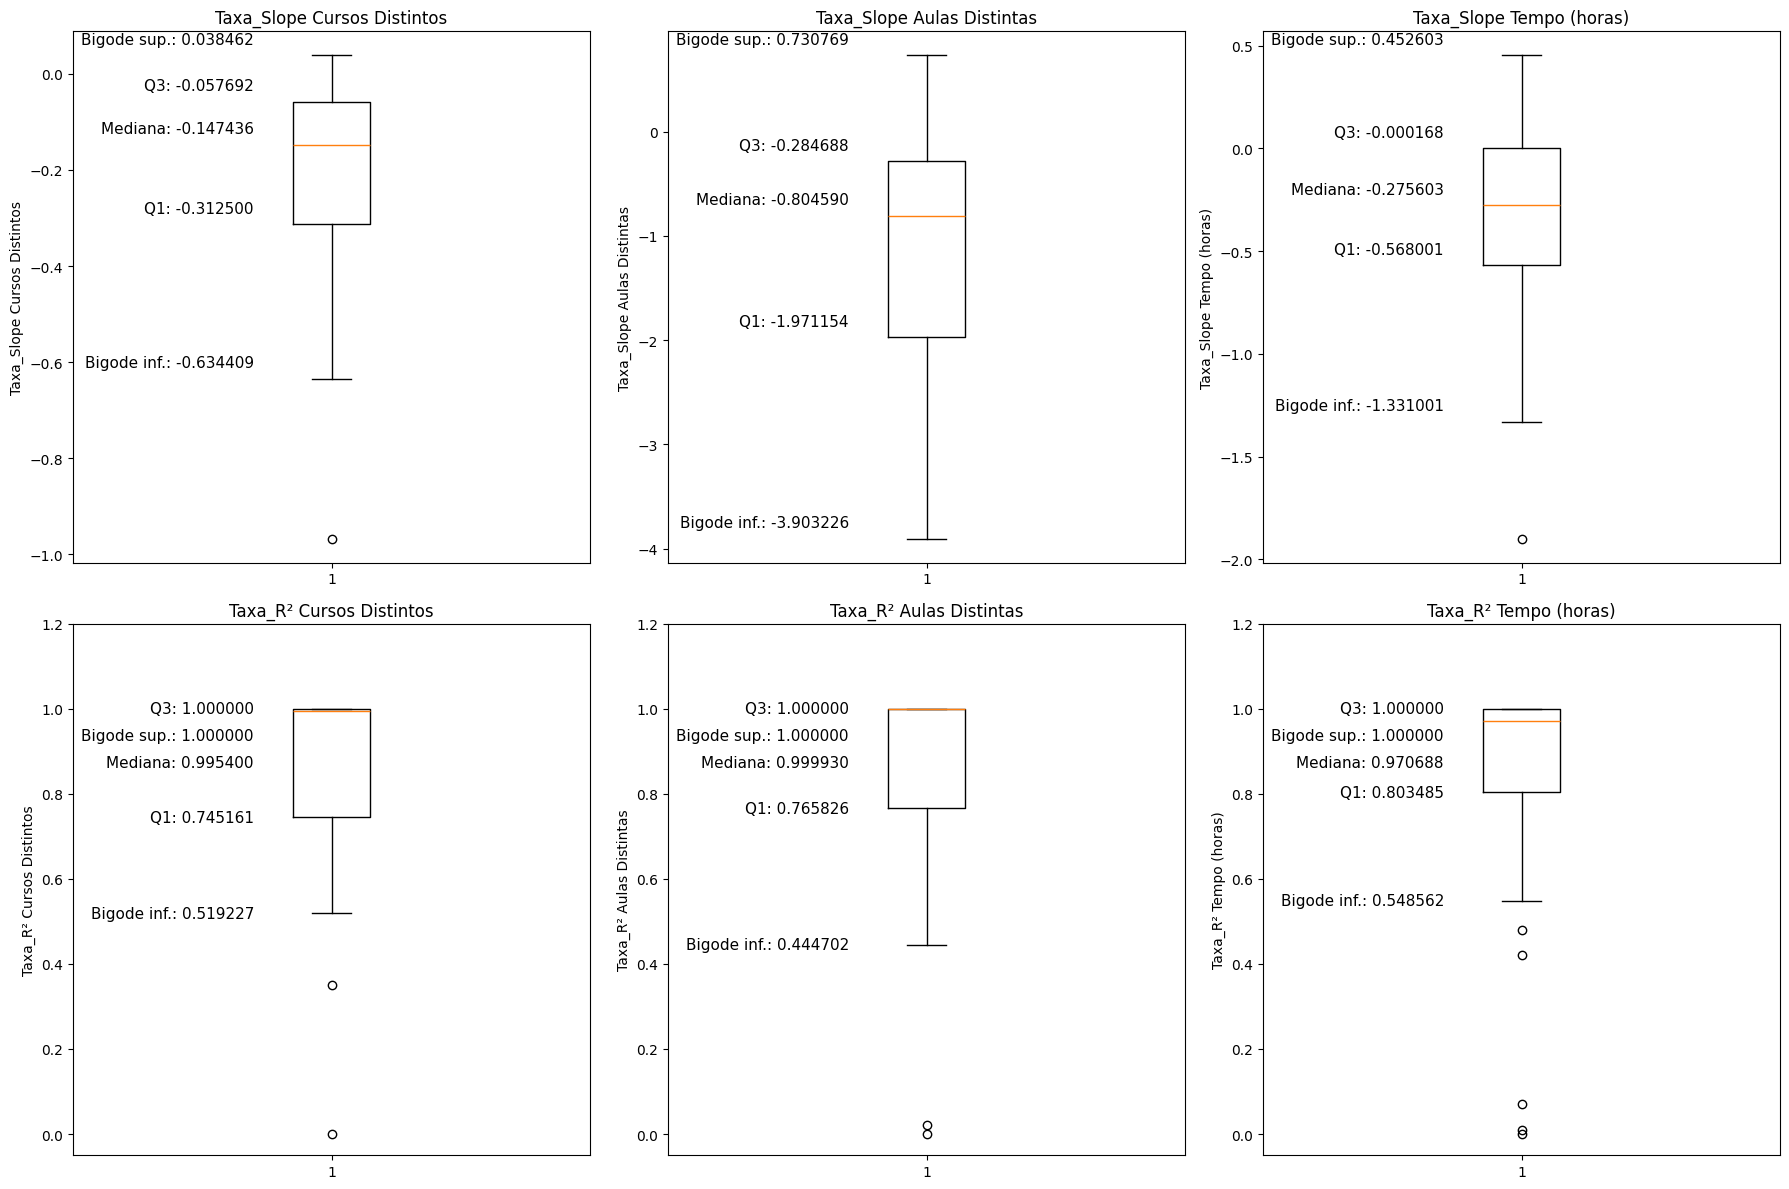

In [0]:
# Boxplot para análise do slope e do R² das taxas de cursos, aulas e tempo assistidos, mostrando a tendência de evolução entre os meses e a confiabilidade dessa tendência, para os alunos pagantes (42).

import matplotlib.pyplot as plt
import pandas as pd
resultado_slope = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope")
df_slope = resultado_slope.toPandas()

metricas_slope = [
    ('taxa_slope_cursos', 'Taxa_Slope Cursos Distintos'),
    ('taxa_slope_aulas', 'Taxa_Slope Aulas Distintas'),
    ('taxa_slope_tempo', 'Taxa_Slope Tempo (horas)')
]
metricas_r2 = [
    ('taxa_r2_cursos', 'Taxa_R² Cursos Distintos'),
    ('taxa_r2_aulas', 'Taxa_R² Aulas Distintas'),
    ('taxa_r2_tempo', 'Taxa_R² Tempo (horas)')
]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (coluna, titulo) in zip(axes[0], metricas_slope):
    dados = pd.to_numeric(df_slope[coluna], errors='coerce').dropna()
    bp = ax.boxplot(dados, vert=True)
    ax.set_title(titulo)
    ax.set_ylabel(titulo)
    mediana = bp['medians'][0].get_ydata()[0]
    q1 = bp['boxes'][0].get_ydata()[0]
    q3 = bp['boxes'][0].get_ydata()[2]
    bigode_inferior = bp['whiskers'][0].get_ydata()[1]
    bigode_superior = bp['whiskers'][1].get_ydata()[1]
    y_min, y_max = ax.get_ylim()
    offset = (y_max - y_min) * 0.03
    for valor, nome in [(mediana, 'Mediana'), (q1, 'Q1'), (q3, 'Q3'),
                         (bigode_inferior, 'Bigode inf.'), (bigode_superior, 'Bigode sup.')]:
        ax.text(0.85, valor + offset, f'{nome}: {valor:.6f}', va='center', ha='right', fontsize=11)

for ax, (coluna, titulo) in zip(axes[1], metricas_r2):
    dados = pd.to_numeric(df_slope[coluna], errors='coerce').dropna()
    bp = ax.boxplot(dados, vert=True)
    ax.set_title(titulo)
    ax.set_ylabel(titulo)
    ax.set_ylim(top=1.2)
    mediana = bp['medians'][0].get_ydata()[0]
    q1 = bp['boxes'][0].get_ydata()[0]
    q3 = bp['boxes'][0].get_ydata()[2]
    bigode_inferior = bp['whiskers'][0].get_ydata()[1]
    bigode_superior = bp['whiskers'][1].get_ydata()[1]
    y_min, y_max = ax.get_ylim()
    espacamento_min = (y_max - y_min) * 0.05

    pontos = sorted(
        [('Mediana', mediana), ('Q1', q1), ('Q3', q3),
         ('Bigode inf.', bigode_inferior), ('Bigode sup.', bigode_superior)],
        key=lambda p: p[1], reverse=True
    )
    pos_anterior = None
    for nome, valor in pontos:
        pos_y = valor if pos_anterior is None else min(valor, pos_anterior - espacamento_min)
        ax.text(0.85, pos_y, f'{nome}: {valor:.6f}', va='center', ha='right', fontsize=11)
        pos_anterior = pos_y

plt.tight_layout()
plt.show()

**_NOTA: Os gráficos box plot da Métrica 09 analisam o comportamento de 42 alunos com acesso registrado em pelo menos 2 meses distintos, em pelo menos 1 aula/curso. Os outros 20, sem base suficiente, ficam fora destes boxplot. Usa-se a taxa (cursos/aulas/horas por dia disponível no mês) em vez do valor absoluto, para que meses parciais não distorçam a comparação com meses completos, onde valores negativos indicam queda nessa taxa ao longo dos meses; positivos, crescimento. Complementando o slope, o R² (0 a 1) indica o quanto essa tendência é confiável: próximo de 1, os meses seguem bem a direção calculada; próximo de 0, os valores oscilam, e o slope representa pouco do comportamento real._**

**Interpretação — Distribuição da Taxa_Slope de Cursos Distintos:** A grande maioria da turma está em queda: metade, cerca de 21 alunos (50%), tem slope de até -0,147 (mediana), e 25% (cerca de 11 alunos) caem mais, com slope de -0,313 ou menos (Q1). Outro grupo de 11 alunos (25%, entre mediana e Q3) tem queda mais leve, entre -0,147 e -0,058 (Q3). Já os 11 alunos (25%) entre -0,058 e 0,038 (Q3 ao bigode superior) são o único grupo sem tendência de queda ao longo do período, em média. Como quase toda a distribuição está no campo negativo (só o extremo superior chega perto de zero, sem ultrapassar muito), o quadro geral é de desaceleração na diversidade de cursos acessados mês a mês — a maior parte da turma está reduzindo a abrangência de cursos distintos ao longo do tempo (talvez focando em um ou dois cursos de maior interesse), e não há, nesta base, nenhum aluno com tendência de crescimento robusto nesse indicador.

**Interpretação — Distribuição da Taxa_R² de Cursos Distintos:** A confiabilidade da tendência é alta para a maior parte da turma: metade, cerca de 21 alunos (50%), tem R² de 0,995 ou mais (mediana), e 75% (cerca de 32 alunos) têm R² de 0,745 ou mais (Q1), indicando que o slope calculado reflete bem o comportamento real na maioria dos casos. Há dois alunos com R² bem mais baixo (0,35 e 0,00, outliers), onde o slope deve ser lido com mais cautela — o comportamento real desses dois provavelmente é de oscilação, não de uma queda ou estabilidade consistente como a reta sugere. No geral, a queda identificada na taxa de Cursos Distintos tem respaldo forte: não é um artefato de dispersão, mas uma tendência real para a maioria da turma.

**Interpretação — Distribuição da Taxa_Slope de Aulas Distintas:** A grande maioria da turma está em queda, e de forma mais acentuada do que na taxa de cursos: metade, cerca de 21 alunos (50%), tem slope de até -0,805 (mediana), e 25% (cerca de 11 alunos) caem bem mais, com slope de -1,971 ou menos (Q1). Outro grupo de 11 alunos (25%, entre mediana e Q3) tem queda mais leve, entre -0,805 e -0,285 (Q3). Já os 11 alunos (25%) entre -0,285 e 0,731 (Q3 ao bigode superior) são o único grupo com chance de tendência de crescimento, embora a faixa cruze o zero. Uma ressalva importante para essa métrica: aulas de 2h a 3h30 representam 38,6% de todas as aulas da base e estão presentes (Validação 8) em 74,47% dos cursos (35 de 47) (Validação 9) — não são exceção, mas a característica predominante da grade. Como o curso 96, geralmente o primeiro na jornada do aluno, tem aulas bem mais curtas, é natural que o aluno complete mais aulas por dia no início e menos ao migrar para os demais cursos, mesmo mantendo o mesmo esforço. Por isso, essa métrica deve ser lida em conjunto com a taxa de tempo (que não depende da duração das aulas) antes de qualquer conclusão sobre desengajamento.

**Interpretação — Distribuição da Taxa_R² de Aulas Distintas:** A confiabilidade da tendência também é alta: metade, cerca de 21 alunos (50%), tem R² de 1,000 (mediana), e 75% (cerca de 32 alunos) têm R² de 0,766 ou mais (Q1), mostrando que a queda identificada na taxa de Aulas Distintas é, na maioria dos casos, uma tendência real e não apenas ruído. Há um grupo de alunos com R² muito baixo, próximo de zero (visível como múltiplos pontos sobrepostos no gráfico), para os quais o slope deve ser interpretado com cautela — nesses casos, a queda acentuada pode refletir oscilação entre meses, e não uma redução consistente no número de aulas distintas. Combinado com a ressalva sobre a duração das aulas, essa métrica pede atenção redobrada: tanto o efeito da migração para aulas mais longas quanto a baixa confiabilidade em parte da base reforçam que a queda aparente não deve ser lida como sinal direto de desengajamento sem cruzar com a taxa de tempo.

**Interpretação — Distribuição da Taxa_Slope de Tempo (horas):** A maioria da turma está em queda: metade, cerca de 21 alunos (50%), tem slope de até -0,276 (mediana), e 25% (cerca de 11 alunos) caem mais, com slope de -0,568 ou menos (Q1). Outro grupo de 11 alunos (25%, entre mediana e Q3) tem queda mais leve, entre -0,276 e 0 (Q3). Já os 11 alunos (25%) entre 0 e 0,453 (Q3 ao bigode superior) têm tendência estável ou de crescimento no tempo dedicado por dia. Diferente das taxas de Cursos e Aulas Distintas (onde quase toda a distribuição é negativa), aqui o Q3 chega a praticamente zero — ou seja, um quarto da turma já não está em queda no tempo dedicado, mesmo reduzindo a diversidade de cursos/aulas acessados. Isso é coerente com o efeito da duração das aulas: um aluno pode acessar menos aulas por dia (por elas serem mais longas) sem necessariamente reduzir o tempo total dedicado ao estudo. Um aluno aparece como outlier extremo, com slope de aproximadamente -1,9 — uma queda de tempo bem mais acentuada que o restante da turma.

**Interpretação — Distribuição da Taxa_R² de Tempo (horas):** A confiabilidade da tendência é um pouco menor que nas outras duas taxas, mas ainda alta para boa parte da turma: metade, cerca de 21 alunos (50%), tem R² de 0,971 ou mais (mediana), e 75% (cerca de 32 alunos) têm R² de 0,803 ou mais (Q1). Há, porém, um grupo relevante de alunos com R² bem baixo, próximo de zero (visíveis como vários pontos sobrepostos na parte inferior do gráfico) — para esses, a tendência de tempo dedicado por dia é pouco confiável, e o número de slope (positivo ou negativo) provavelmente reflete oscilação entre meses, não uma direção real e sustentada. Isso reforça a leitura cuidadosa já sugerida para essa métrica: antes de concluir queda ou estabilidade no tempo dedicado, vale checar também o R² de cada aluno individualmente, já que, diferente de Cursos e Aulas Distintas, aqui a base tem uma parcela maior de tendências pouco confiáveis.

Geração da ABT - Métricas, suas tabelas e variáveis

5 - Número de Acessos e Taxa de Aproveitamento ..... metrica_acessos ..................................... numero_acessos_dias_distintos, taxa_aproveit_acessos

1 - Recência ...................................................................................metrica_recencia ..................................... recencia

2 - Frequência Média na Plataforma ................................... metrica_frequencia ............................... frequencia_media_dias

8 - Progresso e Velocidade do Progresso ......................... metrica_progresso_velocidade ......... progresso, velocidade

11 - Cursos Concluídos e Cursos em Andamento .......... metrica_cursos ....................................... cursos_concluidos, cursos_andamento

6 - Histórico de Número de Acessos .................................... metrica_historico .................................. tendencia_acessos e r2_hist_acessos

9 - Evolução Mensal ..................................................................... evolucao_mensal_slope ................... taxa_slope_cursos, taxa_slope_aulas, taxa_slope_tempo
                                                                                                             
                                                                                        taxa_R2_cursos, taxa_R2_aulas, taxa_R2_tempo

In [0]:
%sql

/* ABT DE ENGAJAMENTO, COM UMA LINHA POR ALUNO PAGANTE E TODAS AS MÉTRICAS CALCULADAS
Objetivo: 1. Criar a ABT de Engajamento, reunindo todas as métricas calculadas em uma linha por aluno_id, na seguinte ordem lógica de interpretação: Cadastro (Data de Cadastro, Dias de Cadastro), seguido das dimensões Presença/Aproveitamento (Número Acessos, Taxa Aproveitamento, Recência, Média Intervalo Acessos), Efetividade (Progresso, Velocidade, Cursos Concluídos, Cursos em Andamento) e Tendência da Evolução (Histórico Acessos e R², Taxa_Slope Cursos/Aulas/Horas e R² de cada uma). 2. A numeração original das métricas (planilha de proposta da tarefa) foi reordenada aqui para uma sequência que facilita a interpretação por aluno. 3. A base de alunos é a união de todos os aluno_id pagantes presentes em qualquer uma das métricas, garantindo que nenhum aluno seja perdido mesmo que falte em alguma tabela específica (62).*/

CREATE OR REPLACE TABLE proj_ead.tabelas_metricas_aluno.abt_engajamento_aluno AS
WITH base_alunos AS (
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_cadastro
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_acessos
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_recencia
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_frequencia
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_progresso_velocidade
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_cursos
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.metrica_historico
    UNION
    SELECT aluno_id FROM proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope
)
SELECT
    b.aluno_id,
    cd.data_cadastro,
    cd.dias_cadastro,
    ac.numero_acessos_dias_distintos AS numero_acessos,
    ac.taxa_aproveit_acessos,
    r.recencia AS recencia_dias,
    f.frequencia_media_dias AS media_intervalo_acessos_dias,
    pv.progresso AS progresso_pct,
    pv.velocidade AS velocidade_pct_dia,
    c.cursos_concluidos,
    c.cursos_andamento,
    h.tendencia_acessos AS historico_acessos,
    h.r2_hist_acessos AS r2_historico_acessos,
    s.taxa_slope_cursos,
    s.taxa_slope_aulas,
    s.taxa_slope_tempo AS taxa_slope_horas,
    s.taxa_r2_cursos,
    s.taxa_r2_aulas,
    s.taxa_r2_tempo AS taxa_r2_horas
FROM base_alunos b
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_cadastro cd ON b.aluno_id = cd.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_acessos ac ON b.aluno_id = ac.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_recencia r ON b.aluno_id = r.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_frequencia f ON b.aluno_id = f.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_progresso_velocidade pv ON b.aluno_id = pv.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_cursos c ON b.aluno_id = c.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.metrica_historico h ON b.aluno_id = h.aluno_id
LEFT JOIN proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope s ON b.aluno_id = s.aluno_id
ORDER BY b.aluno_id;

SELECT * FROM proj_ead.tabelas_metricas_aluno.abt_engajamento_aluno LIMIT 63;

aluno_id,data_cadastro,dias_cadastro,numero_acessos,taxa_aproveit_acessos,recencia_dias,media_intervalo_acessos_dias,progresso_pct,velocidade_pct_dia,cursos_concluidos,cursos_andamento,historico_acessos,r2_historico_acessos,taxa_slope_cursos,taxa_slope_aulas,taxa_slope_horas,taxa_r2_cursos,taxa_r2_aulas,taxa_r2_horas
207,2024-05-08,628,0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
428,2024-09-05,508,1,0.000000,5.000000,null,0.000000,0.000000,0,0,null,null,null,null,null,null,null,null
769,2025-07-24,186,21,0.857143,1.000000,2.900000,2.198777,0.037267,0,1,-0.371429,0.254135,0.019231,0.076923,0.170027,0.867336,0.444702,0.573969
784,2025-08-04,175,0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
882,2025-09-26,122,11,1.000000,8.000000,4.900000,1.491104,0.026160,1,2,-0.714286,0.601926,-0.268817,-3.075268,-0.273882,1.000000,1.000000,1.000000
1033,2025-10-24,94,21,0.666667,7.000000,2.600000,2.096368,0.035532,0,1,-0.828571,0.471148,0.000000,0.000000,-0.000671,0.000000,0.000000,0.000003
1078,2025-11-18,69,0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
1079,2025-11-18,69,14,1.000000,18.000000,3.769231,0.313450,0.004678,0,1,-0.392857,0.102891,-0.044665,0.151365,-0.033062,1.000000,1.000000,1.000000
1080,2025-11-18,69,24,0.958333,4.000000,2.782609,3.366974,0.049514,1,8,-0.392857,0.094531,-0.307693,-2.923077,-0.574931,0.734885,0.778290,0.720379
1083,2025-11-18,69,6,0.000000,10.000000,11.600000,0.000029,0.000000,0,0,-0.142857,0.117647,0.000000,0.000000,0.000006,1.000000,1.000000,0.750000


**_Exemplos de análise de comportamento de alunos conforme as métricas calculadas. As interpretações abaixo são sempre dos alunos 1086, 1088 e 1222, os mesmos destacados no boxplot da métrica 06 (Histórico de Número de Acessos por Período). Para que os gráficos de linha abaixo das análises mostrem esses alunos especificamente, é necessário garantir que seus ids estejam nos widgets (aluno_1, aluno_2 e aluno_3 nos gráficos comparativos; aluno_4 no gráfico detalhado da métrica 06; aluno_5 no gráfico detalhado da métrica 09)._**

Análise anterior a novas métricas

**Aluno 1086 — Leitura das métricas:**

- **Número de Acessos:** 18 dias distintos de acesso ao longo do período.
- **Recência:** 39 dias sem acessar até a data de referência.
- **Média Intervalo de Acessos:** 1,765 dias entre um acesso e outro, em média — intervalo bastante curto.
- **Histórico de Acessos (slope):** -1,286 — indicando queda acentuada ao longo do período.
- **Progresso:** 1,608% da carga horária total assistida.
- **Velocidade:** 0,023%/dia.
- **Taxa_Slope Cursos/Aulas/Horas:** todos negativos (-0,122 / -1,089 / -0,616).

**Conclusão:** Há uma contradição temporal clara: a Média de Intervalo de Acessos (1,765 dias) mostra que, enquanto ativo, o aluno tinha um ritmo bastante frequente — mas a Recência de 39 dias mostra que esse padrão parou há mais de um mês. O slope de Histórico de Acessos, um dos mais negativos visto até aqui, e as três taxas de Evolução Mensal também negativas, reforçam que essa não foi uma parada repentina isolada, mas um processo de queda que já vinha ocorrendo antes do afastamento total. É um perfil que teve engajamento consistente em algum momento, mas que hoje acumula sinais fortes de queda.




Análise posterior a novas métricas

**Aluno 1086 — Leitura das métricas:**

- **Número de Acessos:** 18 dias distintos
- **Taxa de Aproveitamento dos Acessos:** 0,667
- **Recência:** 39 dias
- **Média de Intervalo de Acessos:** 1,765 dias
- **Progresso:** 1,608%
- **Velocidade:** 0,0233 %/dia
- **Cursos Concluídos:** 1
- **Cursos em Andamento:** 1
- **Histórico de Acessos (slope):** -1,286
- **R² Histórico de Acessos:** 0,831
- **Taxa_Slope Cursos:** -0,122 (R² 1,000)
- **Taxa_Slope Aulas:** -1,089 (R² 1,000)
- **Taxa_Slope Horas:** -0,616 (R² 1,000)

**_Conclusão_**

**1. Presença/Aproveitamento: Reduzida** Acessava com frequência (intervalo de 1,8 dias), mas está há 39 dias sem entrar. Em 1/3 dos dias de acesso só clicou.

**2. Direção: Declinante** Slope de acessos negativo com R² 0,83, mostra que a queda é razoavelmente confiável. Cursos, Aulas e Horas também caem, com R² = 1,00, confirmando a confiabilidade no slope calculado.

**3. Efetividade: Consistente** Progresso de 1,6% e velocidade de 0,0233%/dia. 1 curso concluído e 1 em andamento.Houve avanço.

**Resumo: aluno acessava com frequência, mas hoje está parado, em queda e com avanço limitado.**

Análise anterior as novas métricas

**Aluno 1088 — Leitura das métricas:**

- **Número de Acessos:** 7 dias distintos de acesso ao longo do período.
- **Recência:** 3 dias sem acessar até a data de referência.
- **Média Intervalo de Acessos:** 3,5 dias entre um acesso e outro, em média.
- **Histórico de Acessos (slope):** 0,607 — tendência positiva ao longo do período.
- **Progresso:** 0,662% da carga horária total assistida.
- **Velocidade:** 0,028%/dia.
- **Taxa_Slope Cursos/Aulas/Horas:** nulos nos três — sem pelo menos 2 meses de atividade real para calcular tendência de Evolução Mensal.

**Conclusão:** Os números convergem para um único cenário: o aluno concentrou seus 7 acessos em um período recente, muito provavelmente apenas no mês de janeiro. A recência de 3 dias e o intervalo médio de 3,5 dias mostram atividade recente e frequente; o slope positivo de Histórico de Acessos confirma crescimento dentro da janela coberta; e o fato de as três taxas de Evolução Mensal serem nulas (exigindo pelo menos 2 meses com atividade real) indica que essa atividade não se estendeu por mais de um mês do período de 3 meses analisado. Juntando essas peças, o quadro mais provável é o de um aluno que começou a acessar a plataforma de forma consistente apenas recentemente, sem histórico de engajamento nos meses anteriores — um perfil de início de jornada, não de continuidade.


Análise posterior as novas métrica

**Aluno 1088: Leitura das métricas**

- **Número de Acessos:** 7 dias distintos
- **Taxa de Aproveitamento dos Acessos:** 1,000
- **Recência:** 3 dias
- **Média de Intervalo de Acessos:** 3,5 dias
- **Progresso:** 0,662%
- **Velocidade:** 0,0276 %/dia
- **Cursos Concluídos:** 1
- **Cursos em Andamento:** 1
- **Histórico de Acessos (slope):** +0,607
- **R² Histórico de Acessos** 0,737
- **Taxa_Slope Cursos, Aulas e Horas:** null
- **Taxa_R² Cursos, Aulas e Horas:** null

**Conclusão**

**1. Presença/Aproveitamento: Reduzida** Número de acessos baixo (7), mas com acessos regulares (intervalo médio de 3,5 dias) e último acesso há 3 dias: está presente agora. Em todos os dias de acesso estudou (taxa de aproveitamento 1,000).

**2. Direção: Crescente** Histórico de acessos com slope positivo (+0,607) e R² 0,737: alta razoavelmente confiável. Evolução mensal null: não é possível calcular.

**3. Efetividade: Limitado** Progresso de 0,66% e velocidade de 0,0276%/dia, ambos pequenos e compatíveis com acessos recentes. 1 curso concluído e 1 em andamento: avanço real, mas pequeno.

**Resumo:** aluno com acessos recentes e aproveitamento total, em alta, com avanço pequeno compatível com esse início recente.

Análise anterior as novas métricas

**Aluno 1222 — Leitura das métricas:**

- **Número de Acessos:** 5 dias distintos de acesso ao longo do período.
- **Recência:** 20 dias sem acessar até a data de referência.
- **Média Intervalo de Acessos:** 9,75 dias entre um acesso e outro, em média — calculado a partir de poucos acessos (5 dias distintos), o que limita a robustez desse valor.
- **Histórico de Acessos (slope):** -0,371 — tendência de queda ao longo do período.
- **Progresso:** 1,575% da carga horária total assistida.
- **Velocidade:** 0,027%/dia.
- **Taxa_Slope Cursos/Aulas/Horas:** todos negativos, com destaque para uma queda acentuada em Aulas Distintas (-2,795) e Horas (-1,900).

**Conclusão:** O volume de acesso já é baixo (5 dias distintos), e a recência de 20 dias mostra que o aluno está sem acessar há quase três semanas. As taxas de Evolução Mensal, com quedas bem mais acentuadas que o slope geral de Histórico, sugerem que a queda foi mais forte no período mais recente coberto pela base do que ao longo de todo o histórico. No conjunto, é um perfil de baixo volume de atividade com sinais de desaceleração recente pronunciada — um caso que pede atenção, tanto pelo nível já baixo de engajamento quanto pela direção negativa consistente entre as métricas.

Análise posterior as novas métricas

**Aluno 1222: Leitura das métricas**

- **Número de Acessos:** 5 dias distintos
- **Taxa de Aproveitamento dos Acessos:** 1,000
- **Recência:** 20 dias
- **Média de Intervalo de Acessos:** 9,75 dias
- **Progresso:** 1,575%
- **Velocidade:** 0,0267 %/dia
- **Cursos Concluídos:** 1
- **Cursos em Andamento:** 2
- **Histórico de Acessos (slope):** -0,371
- **R² Histórico de Acessos:** 0,273
- **Taxa_Slope Cursos:** -0,481 (R² 1,000)
- **Taxa_Slope Aulas:** -2,795 (R² 1,000)
- **Taxa_Slope Horas:** -1,900 (R² 1,000)

**Conclusão**

**1. Presença/Aproveitamento: Esporádico** Número de acessos baixo (5), com intervalo médio longo (9,75 dias) e último acesso há 20 dias: entra pouco e de forma espaçada. Em todos os dias de acesso estudou (taxa de aproveitamento 1,000).

**2. Direção: Declinante** Histórico de acessos com slope negativo (-0,371) e R² 0,273: tendência de queda, com acessos oscilando. Cursos, Aulas e Horas também caem, com R² 1,00, confirmando a confiabilidade no cálculo do slope.

**3. Efetividade: Limitado** Progresso de 1,58% e velocidade de 0,0267%/dia, ambos pequenos. 1 curso concluído e 2 em andamento: avanço real, mas pequeno.

**Resumo:** aluno que acessa pouco e de forma espaçada, em queda com acessos oscilando, e com avanço pequeno, mas com aproveitamento total nos dias em que acessou.

**_Mais alguns exemplos de análise de alunos, já considerando as novas métricas_**

**Aluno 1231: Leitura das métricas**

- **Número de Acessos:** 2 dias distintos
- **Taxa de Aproveitamento dos Acessos:** 0,000
- **Recência:** 13 dias
- **Média de Intervalo de Acessos:** 27 dias
- **Progresso:** 0,000%
- **Velocidade:** 0,000 %/dia
- **Cursos Concluídos:** 0
- **Cursos em Andamento:** 0
- **Histórico de Acessos (slope):** 0,000
- **R² Histórico de Acessos:** 0,000
- **Taxa_Slope Cursos:** 0,000 (R² 1,000)
- **Taxa_Slope Aulas:** 0,000 (R² 1,000)
- **Taxa_Slope Horas:** 0,000 (R² 1,000)

**Conclusão**

**1. Presença/Aproveitamento: Reduzida** Quase não acessou no período: 2 dias de acesso (número de acessos), com 27 dias entre eles e último acesso há 13 dias. Nos dois dias só clicou (taxa de aproveitamento 0,000).

**2. Direção: Ausente** Histórico de acessos com slope 0,000 e R² 0,000, e Cursos, Aulas e Horas com slope 0,000: valores zerados, sem direção a descrever.

**3. Efetividade: Ausente** Progresso, velocidade, cursos concluídos e em andamento zerados: tempo assistido zero, só cliques.

**Resumo:** aluno que quase não acessou no período, só clicou e não assistiu nenhuma aula, sem direção e sem avanço.

**Aluno 1083: Leitura das métricas**

- **Número de Acessos:** 6 dias distintos
- **Taxa de Aproveitamento dos Acessos:** 0,000
- **Recência:** 10 dias
- **Média de Intervalo de Acessos:** 11,6 dias
- **Progresso:** 0,000029%
- **Velocidade:** 0,000000 %/dia
- **Cursos Concluídos:** 0
- **Cursos em Andamento:** 0
- **Histórico de Acessos (slope):** -0,143
- **R² Histórico de Acessos:** 0,118
- **Taxa_Slope Cursos:** 0,000 (R² 1,000)
- **Taxa_Slope Aulas:** 0,000 (R² 1,000)
- **Taxa_Slope Horas:** 0,000006 (R² 0,750)

**Conclusão**

**1. Presença/Aproveitamento: Esporádico** Número de acessos baixo (6), com intervalo médio longo (11,6 dias) e último acesso há 10 dias: entra pouco e com muito tempo entre os acessos, em média. Em nenhum dia de acesso assistiu aula (taxa de aproveitamento 0,000): só clicou.

**2. Direção: Oscilante** Histórico de acessos com slope levemente negativo (-0,143), com R² baixo (0,118), o que indica que essa tendência negativa vem de oscilação dos pontos e assim representa pouco os acessos. Cursos e Aulas com slope 0,000 e Horas com slope 0,000006: sem variação relevante.

**3. Efetividade: Superficial** Progresso de 0,000029%: houve algum tempo assistido, mas mínimo. Nenhum curso concluído ou em andamento.

**Resumo:** aluno que acessa pouco, com muito tempo entre os acessos, em oscilação, e que consumiu um tempo mínimo de aula.

**Aluno 769: Leitura das métricas**

- Número de Acessos: 21 dias distintos
- Taxa de Aproveitamento dos Acessos: 0,857
- Recência: 1 dia
- Média de Intervalo de Acessos: 2,9 dias
- Progresso: 2,199%
- Velocidade: 0,0373 %/dia
- Cursos Concluídos: 0
- Cursos em Andamento: 1
- Histórico de Acessos (slope): -0,371
- R² Histórico de Acessos: 0,254
- Taxa_Slope Cursos: 0,019 (R² 0,867)
- Taxa_Slope Aulas: 0,077 (R² 0,445)
- Taxa_Slope Horas: 0,170 (R² 0,574)

**Conclusão**

**1. Presença/Aproveitamento: Ativo** Número de acessos alto (21), com intervalo médio curto (2,9 dias) e último acesso há 1 dia: acessa com frequência e está presente agora. Estudou em 86% dos dias de acesso (taxa de aproveitamento 0,857).

**2. Direção: Oscilante** Histórico de acessos com slope levemente negativo (-0,371), com R² baixo (0,254), o que indica que essa tendência negativa vem de oscilação dos pontos e assim representa pouco os acessos. Cursos, Aulas e Horas com slope positivo, com R² entre 0,445 e 0,867: tendência de alta. A queda nos acessos destoa do restante das métricas, que mostram um aluno presente, com bom aproveitamento e conteúdo consumido em alta.

**3. Efetividade: Consistente** Progresso de 2,2% e velocidade de 0,0373%/dia, coerentes com 21 dias de acesso e aproveitamento de 0,857. Nenhum curso concluído e 1 em andamento. Houve avanço.

**Resumo:** aluno presente e com bom aproveitamento, com acessos oscilando e queda nos acessos que destoa do restante, e evolução mensal em alta, com avanço pequeno.

**Nota 1 (flag de eventos):** sugere-se um flag que indique se o período analisado contém evento de calendário conhecido. Quando uma métrica destoar das demais, como o histórico de acessos neste caso, o flag apontaria um evento como possível causa, sem alterar o cálculo nem o rótulo.

**Nota 2 (progresso e meta):** o progresso é calculado sobre toda a carga horária disponível, que pode ser tão grande que nem um ano de estudo seria suficiente para concluí-la. Por isso, o percentual tende a ser baixo mesmo para alunos com muitos acessos e bom aproveitamento. Sugere-se avaliar uma meta de progresso condizente com o período analisado (3 meses de análise, meta para 3 meses; 6 meses, meta para 6 meses), que mostraria melhor a realidade do avanço do aluno.

**Aluno 1221: Leitura das métricas**

- Número de Acessos: 40 dias distintos
- Taxa de Aproveitamento dos Acessos: 1,000
- Recência: 3 dias
- Média de Intervalo de Acessos: 1,436 dias
- Progresso: 7,407%
- Velocidade: 0,1255 %/dia
- Cursos Concluídos: 1
- Cursos em Andamento: 2
- Histórico de Acessos (slope): -0,343
- R² Histórico de Acessos: 0,386
- Taxa_Slope Cursos: -0,128 (R² 0,623)
- Taxa_Slope Aulas: -1,205 (R² 0,608)
- Taxa_Slope Horas: +0,453 (R² 0,964)

**Conclusão**

**1. Presença/Aproveitamento: Ativo**
Número de acessos alto (40), com intervalo médio muito curto (1,4 dias) e último acesso há 3 dias: acessa quase todo dia e está presente agora. Estudou em todos os dias de acesso (taxa de aproveitamento 1,000).

**2. Direção: Oscilante**
Histórico de acessos com slope negativo (-0,343) e R² baixo (0,386): a tendência de queda vem de oscilação dos pontos e representa pouco os acessos. Na evolução mensal, Cursos e Aulas caem e Horas sobe, com R² alto (0,964): o tempo de estudo cresce com menos aulas e cursos distintos, compatível com aulas mais longas.

**3. Efetividade: Consistente**
Progresso de 7,4% e velocidade de 0,1255%/dia. 1 curso concluído e 2 em andamento: avanço real, com conclusão e continuidade em mais de um curso.

**Resumo:** aluno muito presente e com aproveitamento total, com acessos oscilando e tempo de estudo crescendo, e com avanço consistente.

**Aluno 207: Leitura das métricas**

- Número de Acessos: null
- Taxa de Aproveitamento dos Acessos: null
- Recência: null
- Média de Intervalo de Acessos: null
- Progresso: null
- Velocidade: null
- Cursos Concluídos: null
- Cursos em Andamento: null
- Histórico de Acessos (slope): null
- R² Histórico de Acessos: null
- Taxa_Slope Cursos, Aulas e Horas: null
- Taxa_R² Cursos, Aulas e Horas: null

**Conclusão**

**1. Presença/Aproveitamento: Ausente** Todas as métricas da dimensão são nulas: não é possível calcular.

**2. Direção: Ausente** Todas as métricas da dimensão são nulas: não é possível calcular.

**3. Efetividade: Ausente** Todas as métricas da dimensão são nulas: não é possível calcular.

**Resumo:** aluno sem nenhuma métrica calculada no período, o que indica que ele ainda não acessou nenhuma aula.

**Aluno 1092: Leitura das métricas**

- Número de Acessos: 8 dias distintos
- Taxa de Aproveitamento dos Acessos: 1,000
- Recência: 4 dias
- Média de Intervalo de Acessos: 1,714 dias
- Progresso: 1,609%
- Velocidade: 0,1006 %/dia
- Cursos Concluídos: 1
- Cursos em Andamento: 1
- Histórico de Acessos (slope): +0,643
- R² Histórico de Acessos: 0,375
- Taxa_Slope Cursos, Aulas e Horas: null
- Taxa_R² Cursos, Aulas e Horas: null

**Conclusão**

**1. Presença/Aproveitamento: Reduzida**
Número de acessos baixo (8), mas com intervalo médio muito curto (1,7 dias) e último acesso há 4 dias: quando acessa, volta rápido, e está presente agora. Estudou em todos os dias de acesso (taxa de aproveitamento 1,000).

**2. Direção: Crescente**
Histórico de acessos com slope positivo (+0,643) e R² baixo (0,375): a alta é real, mas a reta representa pouco os acessos. Evolução mensal null: acessos em um único mês, o que indica início recente dos acessos.

**3. Efetividade: Consistente**
Progresso de 1,6% e velocidade de 0,1006%/dia, alta. O progresso é compatível com o curto período de estudo, e a velocidade mostra ritmo forte. 1 curso concluído e 1 em andamento: avanço real.

**Resumo:** aluno de início recente nos acessos, com acessos frequentes e em alta, aproveitamento total e ritmo de avanço alto, com progresso compatível com o período curto de estudo.

Próximo aluno da lista: 1209. Analiso agora.

**Aluno 1209: Leitura das métricas**

- Número de Acessos: 1 dia
- Taxa de Aproveitamento dos Acessos: 1,000
- Recência: 27 dias
- Média de Intervalo de Acessos: null
- Progresso: 0,127%
- Velocidade: 0,0047 %/dia
- Cursos Concluídos: 0
- Cursos em Andamento: 1
- Histórico de Acessos (slope): null
- R² Histórico de Acessos: null
- Taxa_Slope Cursos, Aulas e Horas: null
- Taxa_R² Cursos, Aulas e Horas: null

**Conclusão**

**1. Presença/Aproveitamento: Reduzida** Apenas 1 dia de acesso (número de acessos), há 27 dias. Nesse dia estudou (taxa de aproveitamento 1,000). Média de intervalo null: não é possível calcular com um único acesso.

**2. Direção: Ausente** Histórico de acessos e evolução mensal null: não é possível calcular. Sem direção a descrever.

**3. Efetividade: Superficial** Progresso de 0,127% e velocidade de 0,0047%/dia, ambos mínimos. 0 cursos concluídos e 1 em andamento: houve algum tempo assistido, mas o avanço é mínimo.

**Resumo:** aluno com um único dia de acesso, há 27 dias, em que estudou, sem direção calculável e com avanço mínimo.

**Aluno 1033: Leitura das métricas**

- Número de Acessos: 21 dias distintos
- Taxa de Aproveitamento dos Acessos: 0,667
- Recência: 7 dias
- Média de Intervalo de Acessos: 2,6 dias
- Progresso: 2,096%
- Velocidade: 0,0355 %/dia
- Cursos Concluídos: 0
- Cursos em Andamento: 1
- Histórico de Acessos (slope): -0,829
- R² Histórico de Acessos: 0,471
- Taxa_Slope Cursos: 0,000 (R² 0,000)
- Taxa_Slope Aulas: 0,000 (R² 0,000)
- Taxa_Slope Horas: -0,000671 (R² 0,000003)

**Conclusão**

**1. Presença/Aproveitamento: Ativo** Número de acessos alto (21), com intervalo médio curto (2,6 dias) e último acesso há 7 dias: acessa com frequência e está presente. Estudou em 2/3 dos dias de acesso (taxa de aproveitamento 0,667).
 
**2. Direção: Declinante** Histórico de acessos com slope negativo (-0,829) e R² 0,471: queda moderadamente confiável. Na evolução mensal, Cursos, Aulas e Horas com slope zero ou quase zero e R² próximo de zero: a tendência calculada não é confiável.

**3. Efetividade: Consistente** Progresso de 2,1% e velocidade de 0,0355%/dia, coerentes com 21 dias de acesso e aproveitamento de 0,667. Nenhum curso concluído e 1 em andamento: avanço contínuo em um único curso.

**Resumo:** aluno presente e frequente, com queda moderadamente confiável nos acessos, evolução mensal sem tendência confiável e avanço contínuo. Como o número de acessos e alto com alto aproveitamento, e Progresso é condizente com o período em estudo, o tempo deve estar sendo aplicado a apenas um curso, e de duração mais longa.

**Aluno 1080: Leitura das métricas**

- Número de Acessos: 24 dias distintos
- Taxa de Aproveitamento dos Acessos: 0,958
- Recência: 4 dias
- Média de Intervalo de Acessos: 2,783 dias
- Progresso: 3,367%
- Velocidade: 0,0495 %/dia
- Cursos Concluídos: 1
- Cursos em Andamento: 8
- Histórico de Acessos (slope): -0,393
- R² Histórico de Acessos: 0,095
- Taxa_Slope Cursos: -0,308 (R² 0,735)
- Taxa_Slope Aulas: -2,923 (R² 0,778)
- Taxa_Slope Horas: -0,575 (R² 0,720)

**Conclusão**

**1. Presença/Aproveitamento: Ativo**
Número de acessos alto (24), com intervalo médio curto (2,8 dias) e último acesso há 4 dias: acessa com frequência e está presente. Estudou em quase todos os dias de acesso (taxa de aproveitamento 0,958).

**2. Direção: Declinante**
Histórico de acessos com slope negativo (-0,393) e R² muito baixo (0,095): a tendência de queda vem de oscilação dos pontos e representa muito pouco os acessos. Cursos, Aulas e Horas também caem, com R² entre 0,720 e 0,778, confirmando a alta confiabilidade em slope.

**3. Efetividade: Consistente**
Progresso de 3,4% e velocidade de 0,0495%/dia, coerentes com 24 dias de acesso e aproveitamento quase total. 1 curso concluído e 8 em andamento.

**Resumo:** aluno presente e frequente, com aproveitamento quase total, queda nos acessos com tendência pouco representativa, queda confiável na evolução mensal.

**Gráficos de linha:** Referente aos pontos usados nos cálculos dos slopes das métricas 06 e 09, para validação da análise de slope e R2, gráfico para conjunto de 3 alunos (aluno_1 a aluno_3), e gráficos para individuos (aluno_4 e aluno_5)

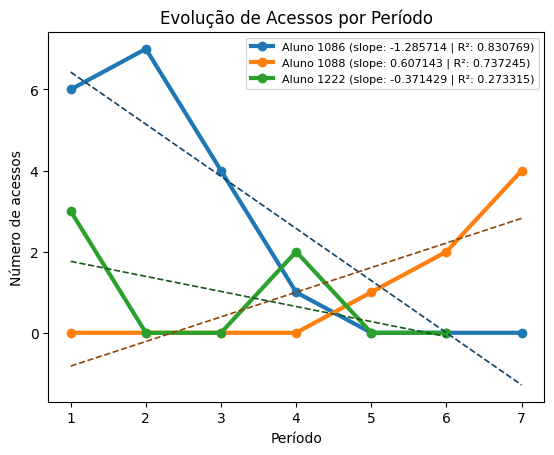

In [0]:
# Objetivo: 1. Gerar gráfico de linha para análise da evolução do número de acessos ao longo dos períodos, para os alunos informados nos widgets, incluindo na legenda o valor do slope (tendência) e do R² (confiabilidade da tendência) de cada aluno. 2. Linha de tendência tracejada, em tom mais escuro da cor de cada aluno, usando o slope da tabela.

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

aluno_1 = dbutils.widgets.get("aluno_1")
aluno_2 = dbutils.widgets.get("aluno_2")
aluno_3 = dbutils.widgets.get("aluno_3")
tamanho_periodo = dbutils.widgets.get("tamanho_periodo")
data_inicio = dbutils.widgets.get("data_inicio")
data_fim = dbutils.widgets.get("data_fim")

df_periodos = spark.sql(f"""
    WITH data_matricula_aluno AS (
        SELECT
            ag.aluno_id,
            GREATEST(DATE('{data_inicio}'), MAX(DATE(TRY_CAST(a.cadastro AS TIMESTAMP)))) AS data_matricula
        FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado ag
        JOIN proj_ead.tabelas_metricas_aluno.alunos_geral a ON ag.aluno_id = a.aluno_id
        WHERE TRY_CAST(a.cadastro AS TIMESTAMP) IS NOT NULL
        GROUP BY ag.aluno_id
    ),
    todos_alunos AS (
        SELECT DISTINCT aluno_id FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado
        WHERE aluno_id IN ({aluno_1}, {aluno_2}, {aluno_3})
    ),
    datas_acesso AS (
        SELECT aluno_id, DATE(ultima_visualizacao) AS data_acesso
        FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
        WHERE ultima_visualizacao IS NOT NULL AND aluno_id IN ({aluno_1}, {aluno_2}, {aluno_3})
        UNION
        SELECT aluno_id, DATE(TRY_CAST(data_conclusao AS TIMESTAMP)) AS data_acesso
        FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
        WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL AND aluno_id IN ({aluno_1}, {aluno_2}, {aluno_3})
    ),
    datas_unicas AS (
        SELECT DISTINCT aluno_id, data_acesso FROM datas_acesso
    ),
    acessos_com_periodo AS (
        SELECT d.aluno_id, d.data_acesso,
            CAST(FLOOR(DATEDIFF(d.data_acesso, m.data_matricula) / CAST({tamanho_periodo} AS DOUBLE)) AS INT) + 1 AS periodo
        FROM datas_unicas d
        JOIN data_matricula_aluno m ON d.aluno_id = m.aluno_id
        WHERE d.data_acesso >= m.data_matricula
    ),
    contagem_por_periodo AS (
        SELECT aluno_id, periodo, COUNT(*) AS acessos
        FROM acessos_com_periodo GROUP BY aluno_id, periodo
    ),
    total_periodos AS (
        SELECT m.aluno_id,
            CAST(CEIL((DATEDIFF(DATE('{data_fim}'), m.data_matricula) + 1) / CAST({tamanho_periodo} AS DOUBLE)) AS INT) AS max_periodo
        FROM data_matricula_aluno m JOIN todos_alunos t ON m.aluno_id = t.aluno_id
    ),
    grade_periodos AS (
        SELECT t.aluno_id, gs AS periodo
        FROM total_periodos t
        LATERAL VIEW explode(sequence(1, t.max_periodo)) AS gs
    )SELECT
        g.aluno_id,
        g.periodo,
        COALESCE(c.acessos, 0) AS acessos
    FROM grade_periodos g
    LEFT JOIN contagem_por_periodo c ON g.aluno_id = c.aluno_id AND g.periodo = c.periodo
    ORDER BY g.aluno_id, g.periodo
""").toPandas()

df_slope_legenda = spark.sql(f"""
    SELECT aluno_id, tendencia_acessos, r2_hist_acessos
    FROM proj_ead.tabelas_metricas_aluno.metrica_historico
    WHERE aluno_id IN ({aluno_1}, {aluno_2}, {aluno_3})
""").toPandas()
df_slope_legenda['tendencia_acessos'] = pd.to_numeric(df_slope_legenda['tendencia_acessos'], errors='coerce')
df_slope_legenda['r2_hist_acessos'] = pd.to_numeric(df_slope_legenda['r2_hist_acessos'], errors='coerce')

ESPESSURA_SERIE = 3.0                 # linha da série (grossa)
ESPESSURA_TENDENCIA = 1.2             # linha de tendência (fina)
FATOR_ESCURECER = 0.55                # 1.0 = mesma cor; menor = mais escuro


def escurecer(cor, fator=FATOR_ESCURECER):
    r, g, b = mcolors.to_rgb(cor)
    return (r * fator, g * fator, b * fator)


fig, ax = plt.subplots()

for aluno in df_periodos['aluno_id'].unique():
    dados_aluno = df_periodos[df_periodos['aluno_id'] == aluno]
    linha = df_slope_legenda[df_slope_legenda['aluno_id'] == aluno]
    slope_valor = linha['tendencia_acessos'].iloc[0] if not linha.empty else float('nan')
    r2_valor = linha['r2_hist_acessos'].iloc[0] if not linha.empty else float('nan')
    slope_txt = f'{slope_valor:.6f}' if pd.notna(slope_valor) else 'N/A'
    r2_txt = f'{r2_valor:.6f}' if pd.notna(r2_valor) else 'N/A'
    label = f'Aluno {aluno} (slope: {slope_txt} | R²: {r2_txt})'

    serie, = ax.plot(dados_aluno['periodo'], dados_aluno['acessos'], marker='o',
                     linewidth=ESPESSURA_SERIE, label=label)

    # Linha de tendência: usa o slope da tabela e passa pela média dos pontos
    # (propriedade da reta de mínimos quadrados). Premissa: o slope da tabela
    # é por período (eixo X = número do período).
    if len(dados_aluno) >= 2 and pd.notna(slope_valor):
        x = dados_aluno['periodo']
        y_tendencia = dados_aluno['acessos'].mean() + slope_valor * (x - x.mean())
        ax.plot(x, y_tendencia, linestyle='--', linewidth=ESPESSURA_TENDENCIA,
                color=escurecer(serie.get_color()), zorder=5)

plt.title('Evolução de Acessos por Período')
plt.xlabel('Período')
plt.ylabel('Número de acessos')
plt.legend(fontsize=8)
plt.show()

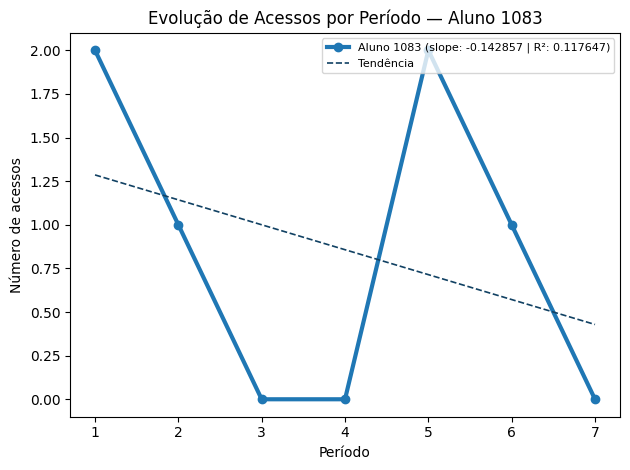

In [0]:
# Objetivo: 1. Gerar gráfico de linha para análise da evolução do histórico de número de acessos ao longo dos períodos, para o aluno informado no widget aluno_4 com mais detalhes, incluindo na legenda o valor do slope (tendência) e do R² (confiabilidade da tendência). 2. Linha de tendência tracejada, em tom mais escuro da cor da série, usando o slope da tabela.


import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

aluno_4 = dbutils.widgets.get("aluno_4")
tamanho_periodo = dbutils.widgets.get("tamanho_periodo")
data_inicio = dbutils.widgets.get("data_inicio")
data_fim = dbutils.widgets.get("data_fim")

df_periodos = spark.sql(f"""
    WITH data_matricula_aluno AS (
        SELECT
            ag.aluno_id,
            GREATEST(DATE('{data_inicio}'), MAX(DATE(TRY_CAST(a.cadastro AS TIMESTAMP)))) AS data_matricula
        FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado ag
        JOIN proj_ead.tabelas_metricas_aluno.alunos_geral a ON ag.aluno_id = a.aluno_id
        WHERE TRY_CAST(a.cadastro AS TIMESTAMP) IS NOT NULL
        GROUP BY ag.aluno_id
    ),
    todos_alunos AS (
        SELECT DISTINCT aluno_id FROM proj_ead.tabelas_metricas_aluno.alunos_geral_filtrado
        WHERE aluno_id = {aluno_4}
    ),
    datas_acesso AS (
        SELECT aluno_id, DATE(ultima_visualizacao) AS data_acesso
        FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
        WHERE ultima_visualizacao IS NOT NULL AND aluno_id = {aluno_4}
        UNION
        SELECT aluno_id, DATE(TRY_CAST(data_conclusao AS TIMESTAMP)) AS data_acesso
        FROM proj_ead.tabelas_metricas_aluno.progresso_total_filtrado
        WHERE TRY_CAST(data_conclusao AS TIMESTAMP) IS NOT NULL AND aluno_id = {aluno_4}
    ),
    datas_unicas AS (
        SELECT DISTINCT aluno_id, data_acesso FROM datas_acesso
    ),
    acessos_com_periodo AS (
        SELECT d.aluno_id, d.data_acesso,
            CAST(FLOOR(DATEDIFF(d.data_acesso, m.data_matricula) / CAST({tamanho_periodo} AS DOUBLE)) AS INT) + 1 AS periodo
        FROM datas_unicas d
        JOIN data_matricula_aluno m ON d.aluno_id = m.aluno_id
        WHERE d.data_acesso >= m.data_matricula
    ),
    contagem_por_periodo AS (
        SELECT aluno_id, periodo, COUNT(*) AS acessos
        FROM acessos_com_periodo GROUP BY aluno_id, periodo
    ),
    total_periodos AS (
        SELECT m.aluno_id,
            CAST(CEIL((DATEDIFF(DATE('{data_fim}'), m.data_matricula) + 1) / CAST({tamanho_periodo} AS DOUBLE)) AS INT) AS max_periodo
        FROM data_matricula_aluno m JOIN todos_alunos t ON m.aluno_id = t.aluno_id
    ),
    grade_periodos AS (
        SELECT t.aluno_id, gs AS periodo
        FROM total_periodos t
        LATERAL VIEW explode(sequence(1, t.max_periodo)) AS gs
    )SELECT
        g.aluno_id,
        g.periodo,
        COALESCE(c.acessos, 0) AS acessos
    FROM grade_periodos g
    LEFT JOIN contagem_por_periodo c ON g.aluno_id = c.aluno_id AND g.periodo = c.periodo
    ORDER BY g.aluno_id, g.periodo
""").toPandas()

df_slope_legenda = spark.sql(f"""
    SELECT aluno_id, tendencia_acessos, r2_hist_acessos
    FROM proj_ead.tabelas_metricas_aluno.metrica_historico
    WHERE aluno_id = {aluno_4}
""").toPandas()
df_slope_legenda['tendencia_acessos'] = pd.to_numeric(df_slope_legenda['tendencia_acessos'], errors='coerce')
df_slope_legenda['r2_hist_acessos'] = pd.to_numeric(df_slope_legenda['r2_hist_acessos'], errors='coerce')

ESPESSURA_SERIE = 3.0                 # linha da série (grossa)
ESPESSURA_TENDENCIA = 1.2             # linha de tendência (fina)
FATOR_ESCURECER = 0.55                # 1.0 = mesma cor; menor = mais escuro
COR_SERIE = 'tab:blue'


def escurecer(cor, fator=FATOR_ESCURECER):
    r, g, b = mcolors.to_rgb(cor)
    return (r * fator, g * fator, b * fator)


slope_valor = df_slope_legenda['tendencia_acessos'].iloc[0] if not df_slope_legenda.empty else float('nan')
r2_valor = df_slope_legenda['r2_hist_acessos'].iloc[0] if not df_slope_legenda.empty else float('nan')
slope_txt = f'{slope_valor:.6f}' if pd.notna(slope_valor) else 'N/A'
r2_txt = f'{r2_valor:.6f}' if pd.notna(r2_valor) else 'N/A'
label = f'Aluno {aluno_4} (slope: {slope_txt} | R²: {r2_txt})'

fig, ax = plt.subplots()

ax.plot(df_periodos['periodo'], df_periodos['acessos'], marker='o',
        linewidth=ESPESSURA_SERIE, color=COR_SERIE, label=label)

# Linha de tendência: usa o slope da tabela e passa pela média dos pontos
# (propriedade da reta de mínimos quadrados). Premissa: o slope da tabela
# é por período (eixo X = número do período).
if len(df_periodos) >= 2 and pd.notna(slope_valor):
    x = df_periodos['periodo']
    y_tendencia = df_periodos['acessos'].mean() + slope_valor * (x - x.mean())
    ax.plot(x, y_tendencia, linestyle='--', linewidth=ESPESSURA_TENDENCIA,
            color=escurecer(COR_SERIE), zorder=5, label='Tendência')

ax.set_title(f'Evolução de Acessos por Período — Aluno {aluno_4}')
ax.set_xlabel('Período')
ax.set_ylabel('Número de acessos')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [0]:
# Objetivo: 1. Carregar volume_final e tempo_final como DataFrames Spark, usados na célula seguinte para plotar a evolução mensal individual dos alunos selecionados.


resultado_volume = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.volume_final")
resultado_tempo = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.tempo_final")

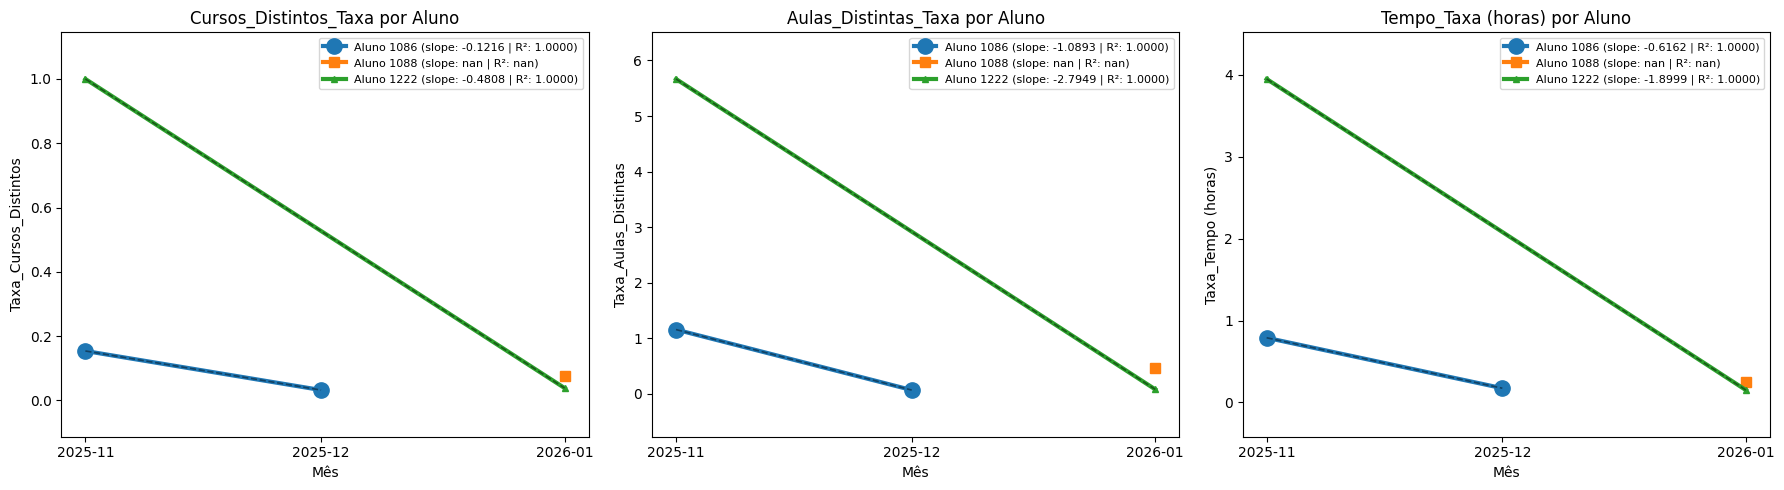

In [0]:
# Objetivo: 1. Gerar gráfico de linha com a evolução mensal das taxas (cursos, aulas e tempo) de até 3 alunos selecionados via widgets (aluno_1, aluno_2, aluno_3), com o respectivo slope e R² (confiabilidade da tendência) de cada um na legenda — para inspeção individual do comportamento por trás dos valores agregados no boxplot anterior. 2. Meses sem dado (NULL) são ignorados ao desenhar a linha, conectando diretamente os meses com valor real, da mesma forma que o cálculo do slope trata os intervalos. 3. Linha de tendência tracejada, em tom mais escuro da cor de cada aluno, usando o slope da tabela.


import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import pandas as pd

aluno_1 = int(dbutils.widgets.get("aluno_1"))
aluno_2 = int(dbutils.widgets.get("aluno_2"))
aluno_3 = int(dbutils.widgets.get("aluno_3"))
alunos_selecionados = [aluno_1, aluno_2, aluno_3]

resultado_slope = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope")

df_volume = resultado_volume.toPandas()
df_tempo = resultado_tempo.toPandas()
df_slope = resultado_slope.toPandas()

df_volume['cursos_distintos_taxa'] = pd.to_numeric(df_volume['cursos_distintos_taxa'], errors='coerce')
df_volume['aulas_distintas_taxa'] = pd.to_numeric(df_volume['aulas_distintas_taxa'], errors='coerce')
df_tempo['tempo_horas_taxa'] = pd.to_numeric(df_tempo['tempo_horas_taxa'], errors='coerce')

# Mês como data (não string/categoria) e ordenado cronologicamente
df_volume['mes_atividade'] = pd.to_datetime(df_volume['mes_atividade'])
df_tempo['mes_atividade'] = pd.to_datetime(df_tempo['mes_atividade'])
df_volume = df_volume.sort_values(['aluno_id', 'mes_atividade'])
df_tempo = df_tempo.sort_values(['aluno_id', 'mes_atividade'])

# Marcadores distintos por aluno, para linhas sobrepostas continuarem visíveis
marcadores = ['o', 's', '^']          # círculo, quadrado, triângulo
tamanhos_marcador = [11, 7, 4]        # maior no 1º (fica atrás), menor no último (fica na frente)

ESPESSURA_SERIE = 3.0                 # linha da série (grossa)
ESPESSURA_TENDENCIA = 1.2             # linha de tendência (fina)
FATOR_ESCURECER = 0.55                # 1.0 = mesma cor; menor = mais escuro


def escurecer(cor, fator=FATOR_ESCURECER):
    r, g, b = mcolors.to_rgb(cor)
    return (r * fator, g * fator, b * fator)


def plotar_aluno(ax, df_valido, coluna, i, aluno_id, slope, r2):
    """Desenha a série do aluno e a linha de tendência (tracejada, tom mais escuro).

    A tendência usa o slope da tabela e passa pela média dos pontos
    (propriedade da reta de mínimos quadrados). Premissa: o slope da tabela
    é por mês (eixo X = índice de mês, respeitando meses sem dado).
    """
    linha, = ax.plot(df_valido['mes_atividade'], df_valido[coluna],
                     linestyle='-', linewidth=ESPESSURA_SERIE,
                     marker=marcadores[i], markersize=tamanhos_marcador[i],
                     label=f'Aluno {aluno_id} (slope: {slope:.4f} | R²: {r2:.4f})')

    if len(df_valido) >= 2 and pd.notna(slope):
        x_mes = df_valido['mes_atividade'].dt.year * 12 + df_valido['mes_atividade'].dt.month
        y_tendencia = df_valido[coluna].mean() + slope * (x_mes - x_mes.mean())
        ax.plot(df_valido['mes_atividade'], y_tendencia,
                linestyle='--', linewidth=ESPESSURA_TENDENCIA,
                color=escurecer(linha.get_color()), zorder=5)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, aluno_id in enumerate(alunos_selecionados):
    df_v = df_volume[df_volume['aluno_id'] == aluno_id]
    df_t = df_tempo[df_tempo['aluno_id'] == aluno_id]

    slope_aluno = df_slope[df_slope['aluno_id'] == aluno_id].iloc[0]
    slope_cursos = pd.to_numeric(slope_aluno['taxa_slope_cursos'], errors='coerce')
    slope_aulas = pd.to_numeric(slope_aluno['taxa_slope_aulas'], errors='coerce')
    slope_tempo = pd.to_numeric(slope_aluno['taxa_slope_tempo'], errors='coerce')
    r2_cursos = pd.to_numeric(slope_aluno['taxa_r2_cursos'], errors='coerce')
    r2_aulas = pd.to_numeric(slope_aluno['taxa_r2_aulas'], errors='coerce')
    r2_tempo = pd.to_numeric(slope_aluno['taxa_r2_tempo'], errors='coerce')

    df_v_cursos = df_v.dropna(subset=['cursos_distintos_taxa'])
    df_v_aulas = df_v.dropna(subset=['aulas_distintas_taxa'])
    df_t_valido = df_t.dropna(subset=['tempo_horas_taxa'])

    plotar_aluno(axes[0], df_v_cursos, 'cursos_distintos_taxa', i, aluno_id, slope_cursos, r2_cursos)
    plotar_aluno(axes[1], df_v_aulas, 'aulas_distintas_taxa', i, aluno_id, slope_aulas, r2_aulas)
    plotar_aluno(axes[2], df_t_valido, 'tempo_horas_taxa', i, aluno_id, slope_tempo, r2_tempo)

titulos = ['Cursos_Distintos_Taxa por Aluno', 'Aulas_Distintas_Taxa por Aluno', 'Tempo_Taxa (horas) por Aluno']
ylabels = ['Taxa_Cursos_Distintos', 'Taxa_Aulas_Distintas', 'Taxa_Tempo (horas)']

for ax, titulo, ylabel in zip(axes, titulos, ylabels):
    ax.set_title(titulo)
    ax.set_xlabel('Mês')
    ax.set_ylabel(ylabel)
    ax.margins(y=0.15)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

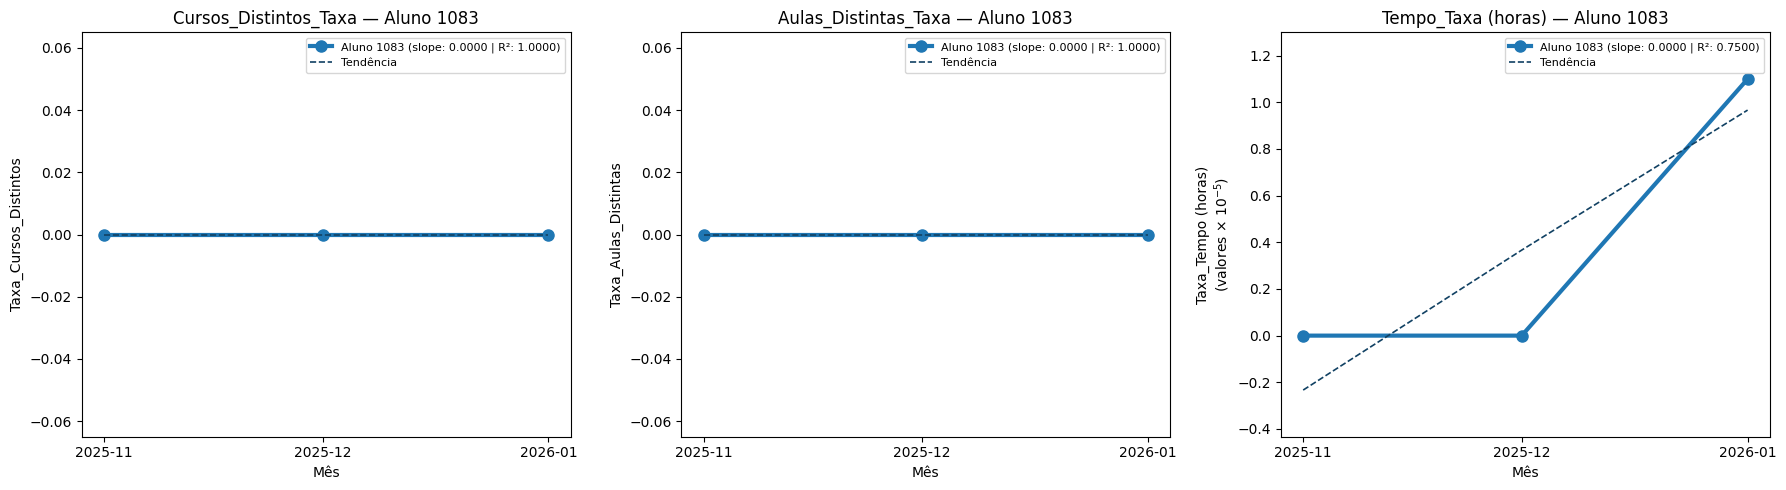

In [0]:
# Objetivo: 1. Gerar gráfico de linha com a evolução mensal das taxas (cursos, aulas e tempo) do aluno selecionado no widget aluno_5, com o respectivo slope e R² na legenda e linha de tendência — com eixo Y próprio e escala ajustada automaticamente à ordem de grandeza dos dados desse aluno (fator ×10ⁿ informado no rótulo do eixo), para enxergar nitidamente pontos e tendência em qualquer aluno com mais detalhes. 2. Meses sem dado (NULL) são ignorados ao desenhar a linha, conectando diretamente os meses com valor real, da mesma forma que o cálculo do slope trata os intervalos.


import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import pandas as pd

aluno_id = int(dbutils.widgets.get("aluno_5"))

resultado_slope = spark.sql("SELECT * FROM proj_ead.tabelas_metricas_aluno.evolucao_mensal_slope")

df_volume = resultado_volume.toPandas()
df_tempo = resultado_tempo.toPandas()
df_slope = resultado_slope.toPandas()

df_volume['cursos_distintos_taxa'] = pd.to_numeric(df_volume['cursos_distintos_taxa'], errors='coerce')
df_volume['aulas_distintas_taxa'] = pd.to_numeric(df_volume['aulas_distintas_taxa'], errors='coerce')
df_tempo['tempo_horas_taxa'] = pd.to_numeric(df_tempo['tempo_horas_taxa'], errors='coerce')

# Mês como data (não string/categoria) e ordenado cronologicamente
df_volume['mes_atividade'] = pd.to_datetime(df_volume['mes_atividade'])
df_tempo['mes_atividade'] = pd.to_datetime(df_tempo['mes_atividade'])

# Filtra somente o aluno_5
df_v = df_volume[df_volume['aluno_id'] == aluno_id].sort_values('mes_atividade')
df_t = df_tempo[df_tempo['aluno_id'] == aluno_id].sort_values('mes_atividade')

slope_aluno = df_slope[df_slope['aluno_id'] == aluno_id].iloc[0]
slope_cursos = pd.to_numeric(slope_aluno['taxa_slope_cursos'], errors='coerce')
slope_aulas = pd.to_numeric(slope_aluno['taxa_slope_aulas'], errors='coerce')
slope_tempo = pd.to_numeric(slope_aluno['taxa_slope_tempo'], errors='coerce')
r2_cursos = pd.to_numeric(slope_aluno['taxa_r2_cursos'], errors='coerce')
r2_aulas = pd.to_numeric(slope_aluno['taxa_r2_aulas'], errors='coerce')
r2_tempo = pd.to_numeric(slope_aluno['taxa_r2_tempo'], errors='coerce')

df_v_cursos = df_v.dropna(subset=['cursos_distintos_taxa'])
df_v_aulas = df_v.dropna(subset=['aulas_distintas_taxa'])
df_t_valido = df_t.dropna(subset=['tempo_horas_taxa'])

ESPESSURA_SERIE = 3.0
ESPESSURA_TENDENCIA = 1.2
FATOR_ESCURECER = 0.55                # 1.0 = mesma cor; menor = mais escuro
COR_SERIE = 'tab:blue'
LIMITE_EXP_INF = -2                   # expoente abaixo disso -> aplica escala (valores < 0,01)
LIMITE_EXP_SUP = 3                    # expoente acima disso -> aplica escala (valores >= 10000)


def escurecer(cor, fator=FATOR_ESCURECER):
    r, g, b = mcolors.to_rgb(cor)
    return (r * fator, g * fator, b * fator)


def expoente_escala(valores):
    """Expoente n tal que dividir por 10**n deixa os valores na casa das unidades.
    Retorna 0 (sem escala) se tudo for 0/NaN ou se a magnitude já for legível."""
    max_abs = np.nanmax(np.abs(valores)) if len(valores) else 0
    if not np.isfinite(max_abs) or max_abs == 0:
        return 0
    exp = int(np.floor(np.log10(max_abs)))
    return exp if (exp < LIMITE_EXP_INF or exp > LIMITE_EXP_SUP) else 0


def plotar_serie(ax, df_valido, coluna, slope, r2, nome_ylabel):
    """Desenha a série e a linha de tendência (tracejada, tom mais escuro).

    A tendência usa o slope da tabela e passa pela média dos pontos.
    Premissa: o slope da tabela é por mês (eixo X = índice de mês).
    A escala do eixo Y é ajustada automaticamente à magnitude dos dados.
    """
    x = df_valido['mes_atividade']
    y = df_valido[coluna].to_numpy(dtype=float)

    tem_tendencia = len(df_valido) >= 2 and pd.notna(slope)
    if tem_tendencia:
        x_mes = (x.dt.year * 12 + x.dt.month).to_numpy(dtype=float)
        y_tend = y.mean() + slope * (x_mes - x_mes.mean())
    else:
        y_tend = np.array([])

    exp = expoente_escala(np.concatenate([y, y_tend]))
    divisor = 10.0 ** exp

    ax.plot(x, y / divisor,
            linestyle='-', linewidth=ESPESSURA_SERIE, marker='o', markersize=8,
            color=COR_SERIE,
            label=f'Aluno {aluno_id} (slope: {slope:.4f} | R²: {r2:.4f})')

    if tem_tendencia:
        ax.plot(x, y_tend / divisor,
                linestyle='--', linewidth=ESPESSURA_TENDENCIA,
                color=escurecer(COR_SERIE), zorder=5, label='Tendência')

    if exp != 0:
        ax.set_ylabel(f'{nome_ylabel}\n(valores × 10$^{{{exp}}}$)')
    else:
        ax.set_ylabel(nome_ylabel)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plotar_serie(axes[0], df_v_cursos, 'cursos_distintos_taxa', slope_cursos, r2_cursos, 'Taxa_Cursos_Distintos')
plotar_serie(axes[1], df_v_aulas, 'aulas_distintas_taxa', slope_aulas, r2_aulas, 'Taxa_Aulas_Distintas')
plotar_serie(axes[2], df_t_valido, 'tempo_horas_taxa', slope_tempo, r2_tempo, 'Taxa_Tempo (horas)')

titulos = [f'Cursos_Distintos_Taxa — Aluno {aluno_id}',
           f'Aulas_Distintas_Taxa — Aluno {aluno_id}',
           f'Tempo_Taxa (horas) — Aluno {aluno_id}']

for ax, titulo in zip(axes, titulos):
    ax.set_title(titulo)
    ax.set_xlabel('Mês')
    ax.margins(y=0.15)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()